# Analyse des données logistiques

Groupe 3.
Participants notebook : Siyaman, Ilicia


Nous utilisons les sept fichiers préparés dans `nettoyage_dataset_logistics.ipynb`. Les données sont fictives. Nous commençons par décrire les expéditions, commandes, réceptions et stocks (CM1), puis comparons les profils de stock (CM2). Nous cherchons ensuite des observations atypiques (CM3) et étudions les échanges entre sites (CM4), puis l'évolution mensuelle des expéditions (CM5).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram


## 1. Charger les données nettoyées

Les identifiants servent aux rapprochements. Les statuts, motifs et classes de risque sont des catégories. Nous ne leur attribuons pas de nombres pour calculer une corrélation. L'ordre de `risk_class` n'étant pas défini par le dictionnaire, nous la traitons ici comme nominale.

In [2]:
dossier = Path("data_clean/logistics")
dates = {
    "erp_business_partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
    "inventory_adjustments": ["adjustment_date"],
    "inventory_month_end": ["reporting_month"],
    "shipments": ["dispatch_time", "arrival_time"],
    "purchase_order_lines": ["order_date", "requested_delivery_date"],
    "goods_receipts": ["receipt_date"]
}
if len(list(dossier.glob("*.csv"))) != 7:
    raise FileNotFoundError("Exécuter d'abord le notebook de nettoyage.")

tables = {f.stem: pd.read_csv(f, parse_dates=dates[f.stem])
          for f in sorted(dossier.glob("*.csv"))}
partenaires = tables["erp_business_partners"]
sites = tables["erp_facilities"]
ajustements = tables["inventory_adjustments"]
stocks = tables["inventory_month_end"].copy()
expeditions = tables["shipments"]
display(pd.Series({nom: len(table) for nom, table in tables.items()}, name="lignes"))

erp_business_partners     80
erp_facilities            30
goods_receipts           610
inventory_adjustments    140
inventory_month_end      500
purchase_order_lines     650
shipments                450
Name: lignes, dtype: int64

Nous utilisons deux fonctions pour les graphiques et une pour la règle IQR. Les diagrammes en barres comptent des catégories. Les histogrammes et les boxplots décrivent des quantités, en séparant les articles et les unités.


In [3]:
def barres(table, colonne, limite=10, ax=None):
    effectifs = table[colonne].fillna("non_renseigne").value_counts()
    if len(effectifs) > limite:
        affichage = effectifs.head(limite).copy()
        affichage.loc["autres modalités"] = effectifs.iloc[limite:].sum()
    else:
        affichage = effectifs
    figure_seule = ax is None
    if figure_seule:
        _, ax = plt.subplots(figsize=(8, 3))
    affichage.sort_values().plot.barh(ax=ax)
    ax.set_title(colonne)
    ax.set_xlabel("Nombre de lignes")
    ax.set_ylabel("")
    if figure_seule:
        plt.tight_layout()
        plt.show()
    return effectifs


def distributions_par_groupe(table, colonne):
    groupes = table.groupby(["item_category", "unit"])
    fig, axes = plt.subplots(groupes.ngroups, 2,
                             figsize=(10, 2.2 * groupes.ngroups), squeeze=False)
    for ligne, (nom_groupe, groupe) in enumerate(groupes):
        categorie, unite = nom_groupe
        groupe[colonne].plot.hist(bins=12, edgecolor="black", ax=axes[ligne, 0])
        axes[ligne, 0].set_title(f"{categorie} ({unite})", fontsize=10)
        axes[ligne, 0].set_ylabel("Nombre de lignes")
        groupe[colonne].plot.box(ax=axes[ligne, 1])
        axes[ligne, 1].set_ylabel(unite)
    plt.tight_layout()
    plt.show()


def hors_iqr(valeurs):
    q1, q3 = valeurs.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (valeurs < q1 - 1.5 * iqr) | (valeurs > q3 + 1.5 * iqr)


## 2. Décrire les partenaires et les sites - CM1

Nous décrivons les rôles et classes de risque des partenaires, puis les catégories et positions des sites.


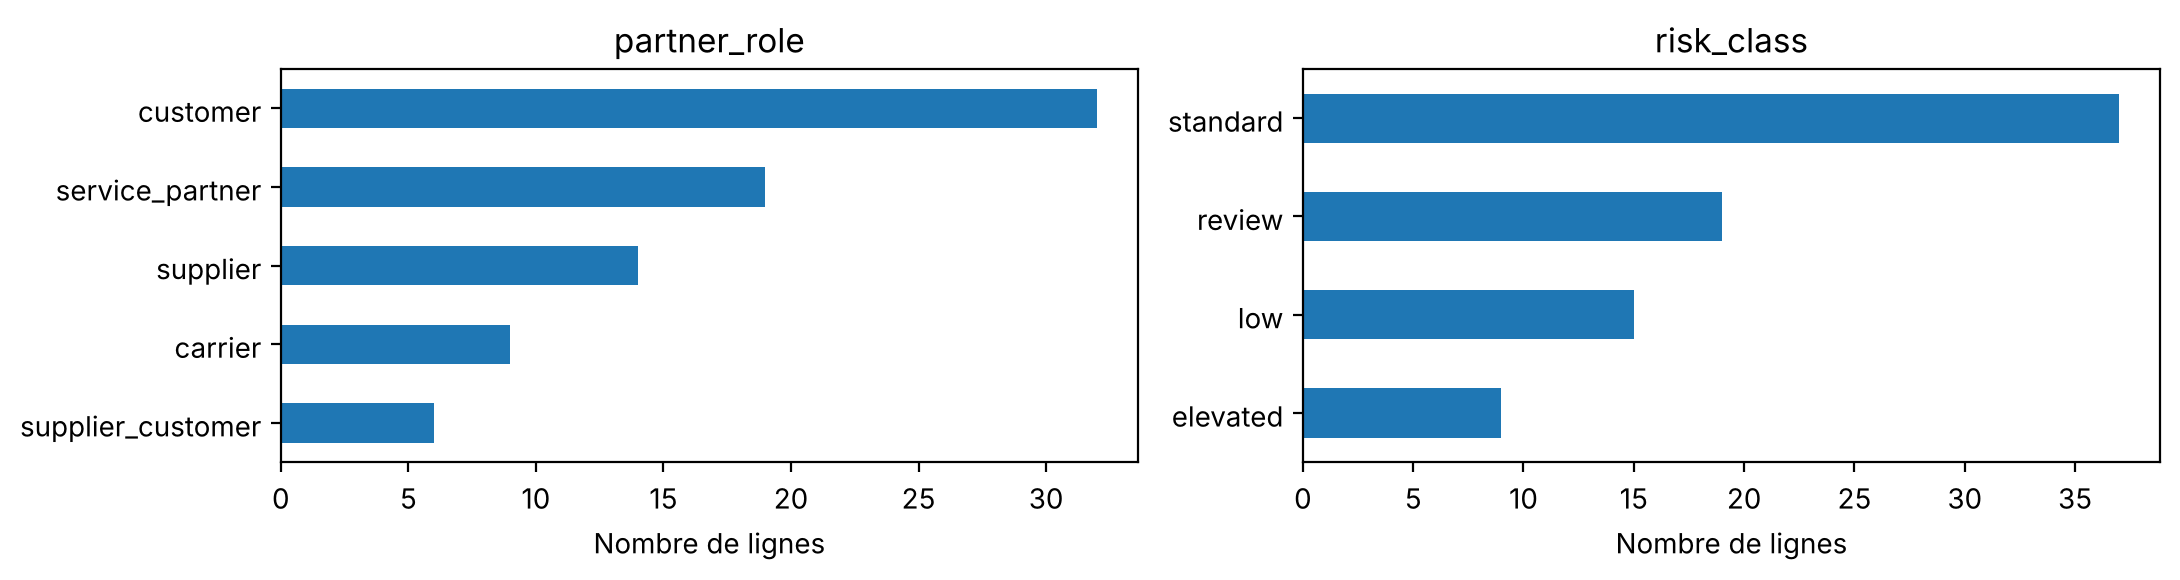

Partenaires sans numéro de registre : 14


partner_role
customer    14
Name: count, dtype: int64

risk_class,elevated,low,review,standard
partner_role,,,,
carrier,1,1,1,6
customer,4,7,9,12
service_partner,2,4,5,8
supplier,1,2,3,8
supplier_customer,1,1,1,3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
roles = barres(partenaires, "partner_role", ax=axes[0])
risques = barres(partenaires, "risk_class", ax=axes[1])
plt.tight_layout()
plt.show()
sans_registre = partenaires[partenaires["external_registration_number"].isna()]
print("Partenaires sans numéro de registre :", len(sans_registre))
display(sans_registre["partner_role"].value_counts())
display(pd.crosstab(partenaires["partner_role"], partenaires["risk_class"]))


Les 80 partenaires comprennent 32 clients, 19 prestataires de service, 14 fournisseurs, 9 transporteurs et 6 partenaires à la fois fournisseurs et clients.

Les 14 numéros de registre absents concernent tous des clients. Leurs noms évoquent des institutions publiques.


Nombre de sites : 30
Capacités de stockage non renseignées : 1


,sites
operating_partner_code,
BP-30078,4
BP-30021,2
BP-30047,1


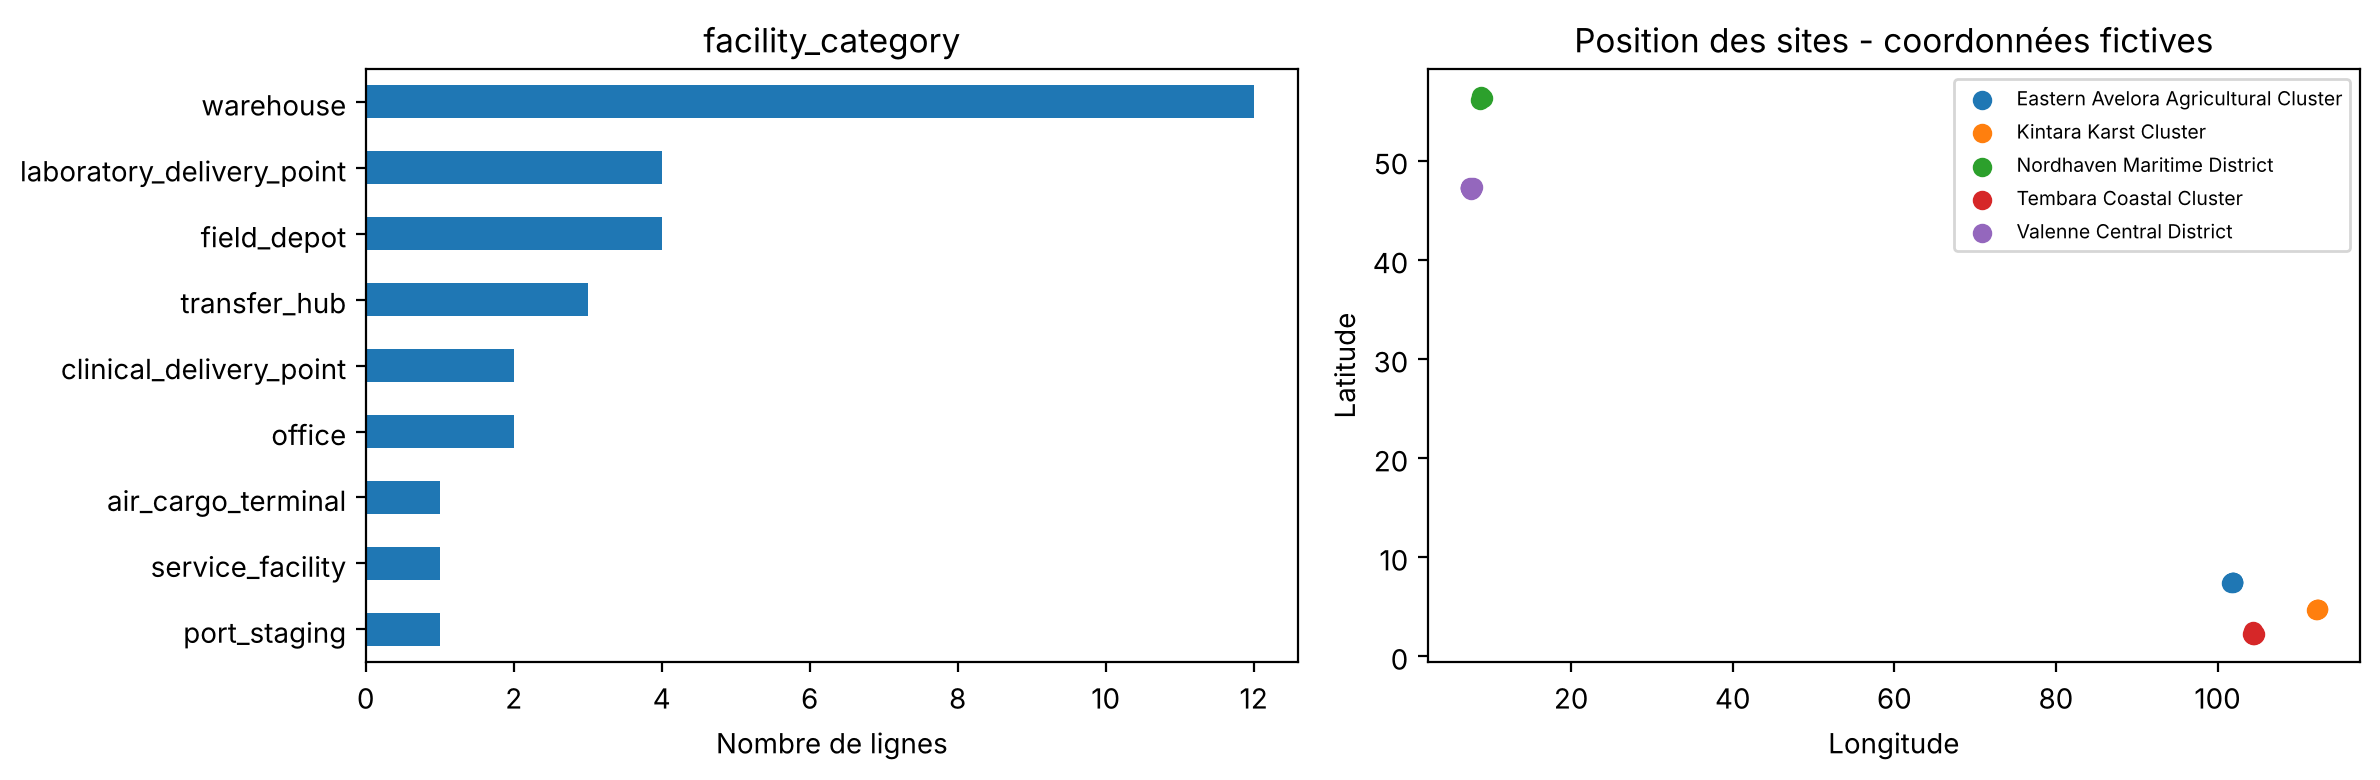

In [5]:
exploitants = sites["operating_partner_code"].value_counts()
print("Nombre de sites :", len(sites))
print("Capacités de stockage non renseignées :", sites["storage_capabilities"].isna().sum())
display(exploitants.head(3).to_frame("sites"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
categories_sites = barres(sites, "facility_category", ax=axes[0])
for region, groupe in sites.groupby("region"):
    axes[1].scatter(groupe["longitude"], groupe["latitude"], label=region)
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title("Position des sites - coordonnées fictives")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()


Il y a 30 sites, dont 12 entrepôts. Meridian en exploite 4 et Asterion 2. Ces référentiels fourniront les noms des sites utilisés plus loin. Une capacité de stockage non renseignée reste inconnue.


## 3. Décrire les expéditions - CM1

### Champs et types de variables

Les numéros et les codes identifient des objets ; leurs chiffres ne mesurent pas une grandeur. Les autres catégories sont nominales : le dictionnaire ne donne pas d'ordre complet pour les statuts, autorisations ou régimes de température. `shipment_leg` indique un rang de tronçon, mais vaut toujours 1 ici. La quantité est discrète dans ce fichier ; l'écart entre les horaires donnera une durée continue.

Le tableau couvre les 16 champs. Nous gardons les libellés pour les comptages : aucun encodage n'est nécessaire. Une numérotation arbitraire des catégories ne permettrait pas d'interpréter leur corrélation.


In [6]:
types_exp = {
    "shipment_number": "Identifiant nominal",
    "shipment_leg": "Rang du tronçon (constant ici)",
    "dispatch_time": "Date et heure",
    "arrival_time": "Date et heure",
    "sender_partner_code": "Identifiant nominal",
    "receiver_partner_code": "Identifiant nominal",
    "origin_facility_code": "Identifiant nominal",
    "destination_facility_code": "Identifiant nominal",
    "carrier_partner_code": "Identifiant nominal",
    "item_category": "Catégorielle nominale",
    "declared_quantity": "Quantitative discrète ici",
    "declared_unit": "Catégorielle nominale",
    "temperature_control_class": "Catégorielle nominale",
    "authorization_class": "Catégorielle nominale",
    "declared_purpose": "Catégorielle nominale",
    "shipment_status": "Catégorielle nominale"
}
display(pd.DataFrame({"type": pd.Series(types_exp),
                      "valeurs_distinctes": expeditions.nunique(),
                      "manquantes": expeditions.isna().sum()}))


,type,valeurs_distinctes,manquantes
shipment_number,Identifiant nominal,450,0
shipment_leg,Rang du tronçon (constant ici),1,0
dispatch_time,Date et heure,441,0
arrival_time,Date et heure,425,17
sender_partner_code,Identifiant nominal,72,0
receiver_partner_code,Identifiant nominal,71,0
origin_facility_code,Identifiant nominal,30,0
destination_facility_code,Identifiant nominal,29,0
carrier_partner_code,Identifiant nominal,9,0
item_category,Catégorielle nominale,18,0


### Répartition des codes et des catégories

Les 450 numéros d'expédition sont distincts : nous ne traçons pas leurs 450 barres identiques. Les partenaires et sites se répètent, ce qui permet d'identifier les acteurs les plus présents. Pour les codes, nous montrons les cinq plus fréquents et regroupons les autres. Toutes les modalités des six autres catégories sont affichées. Les comptages complets restent dans `repartitions_exp`.


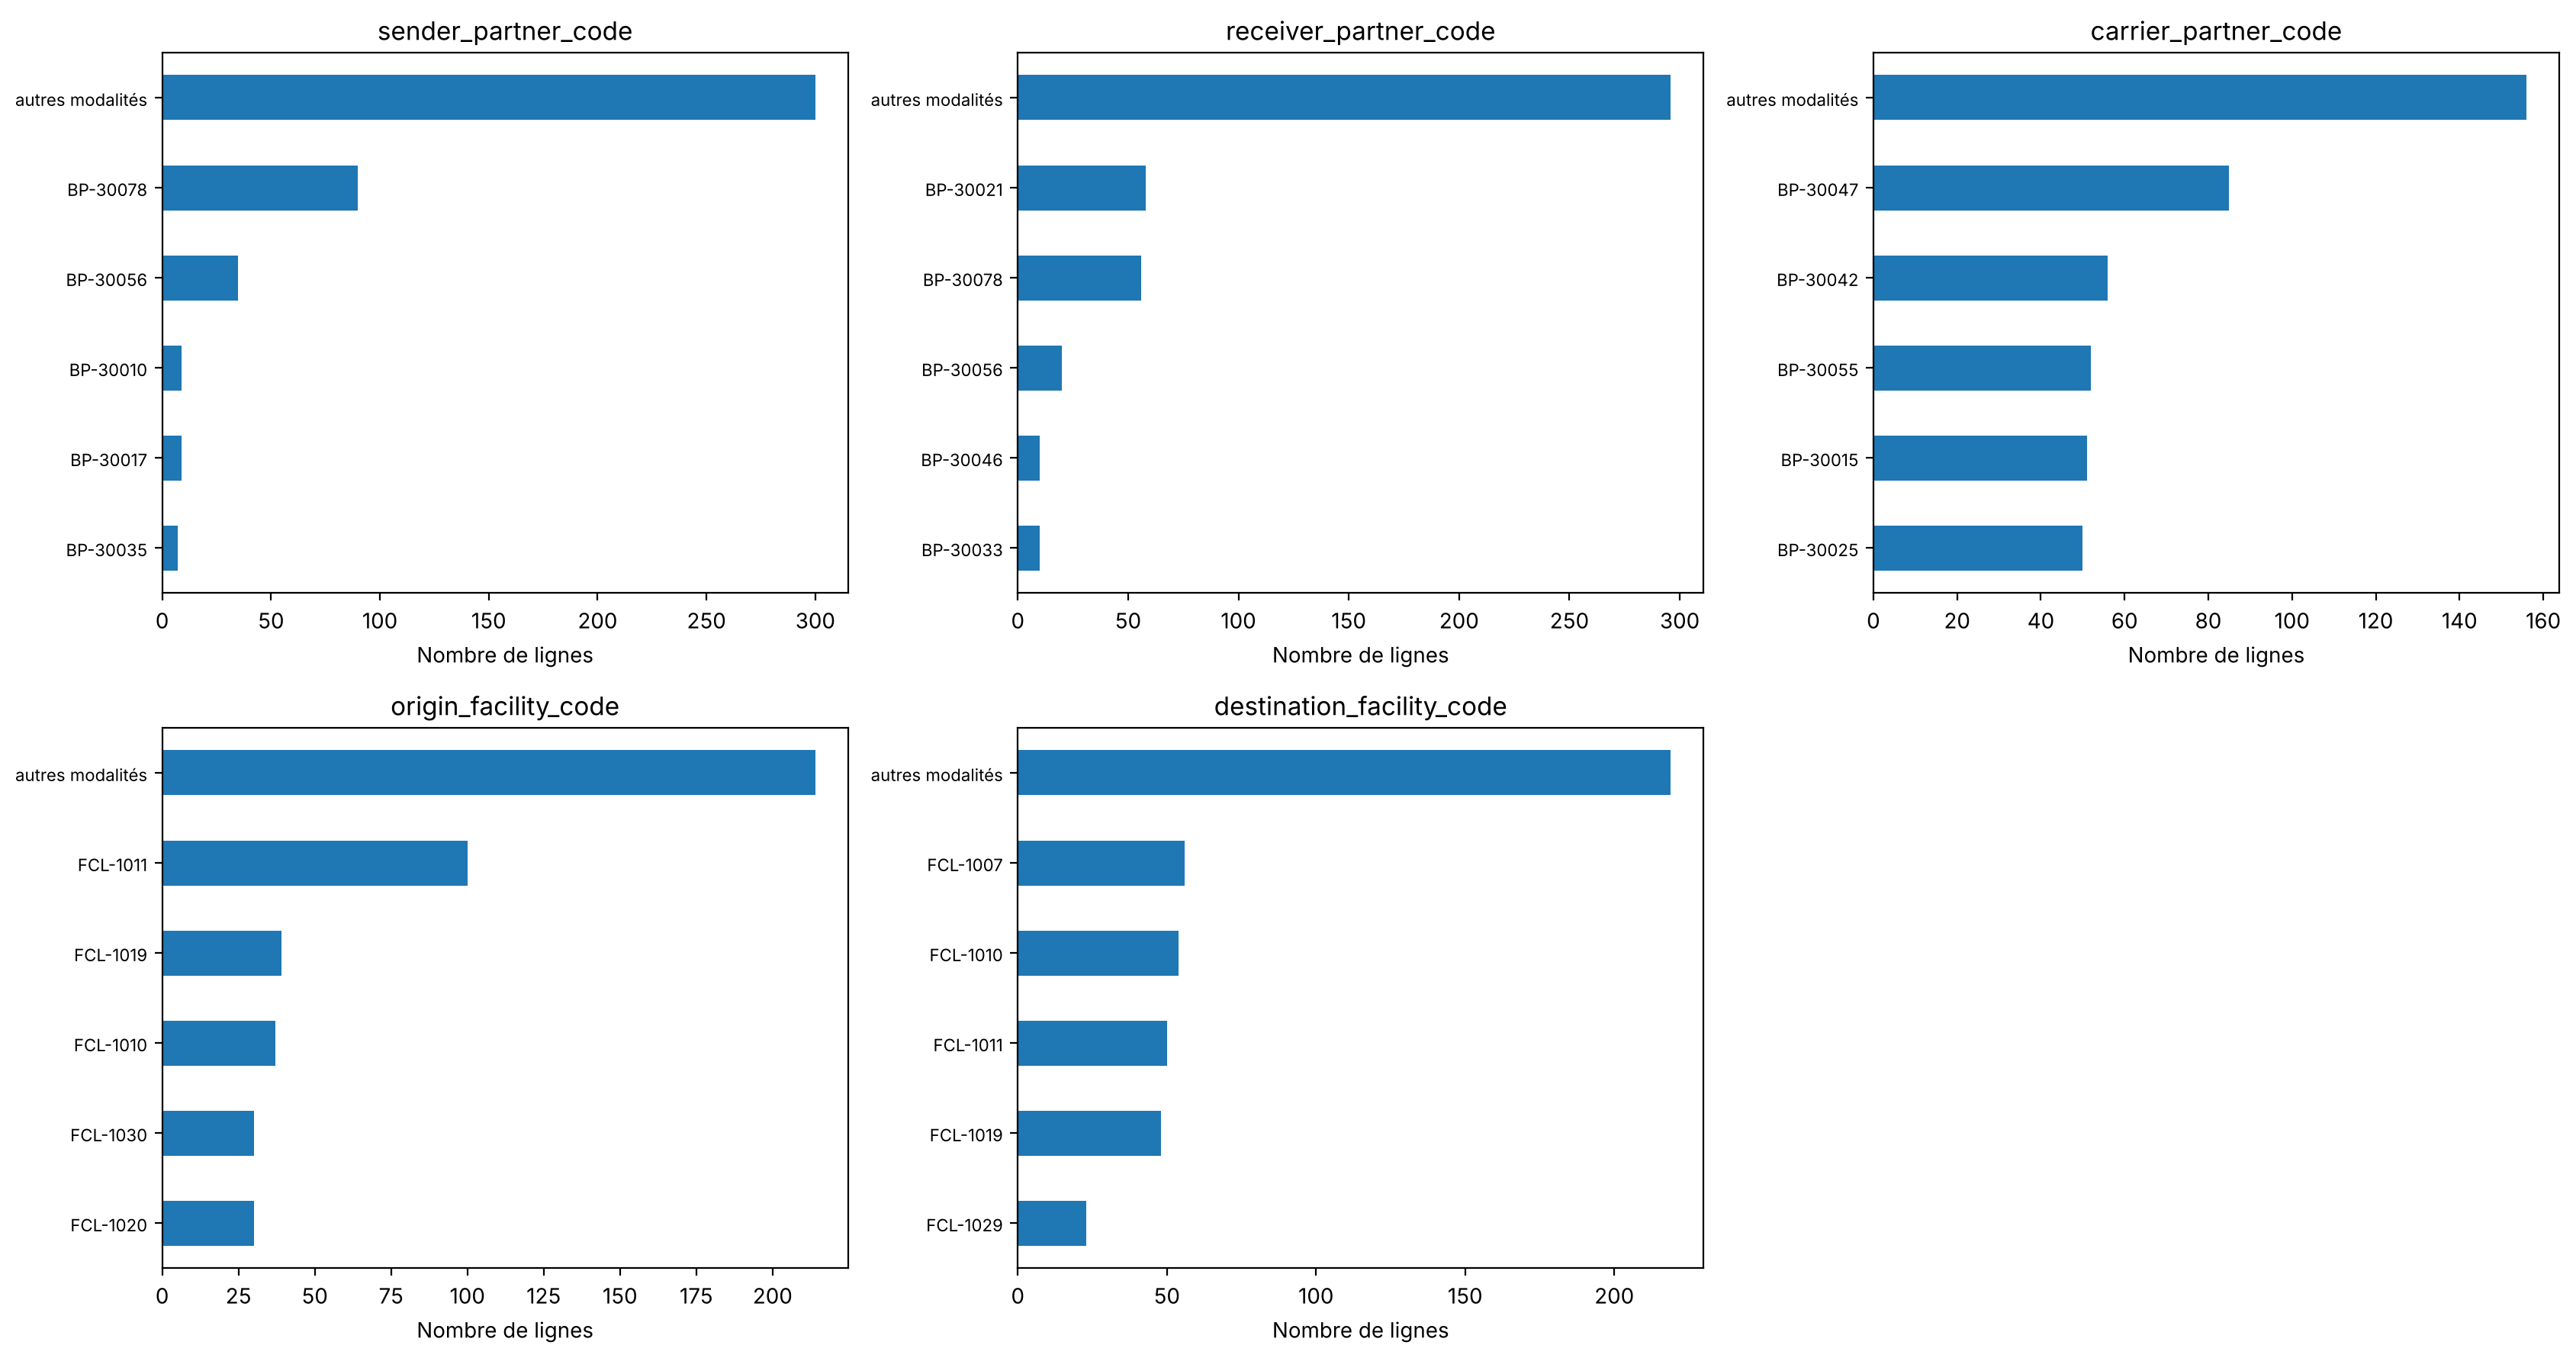

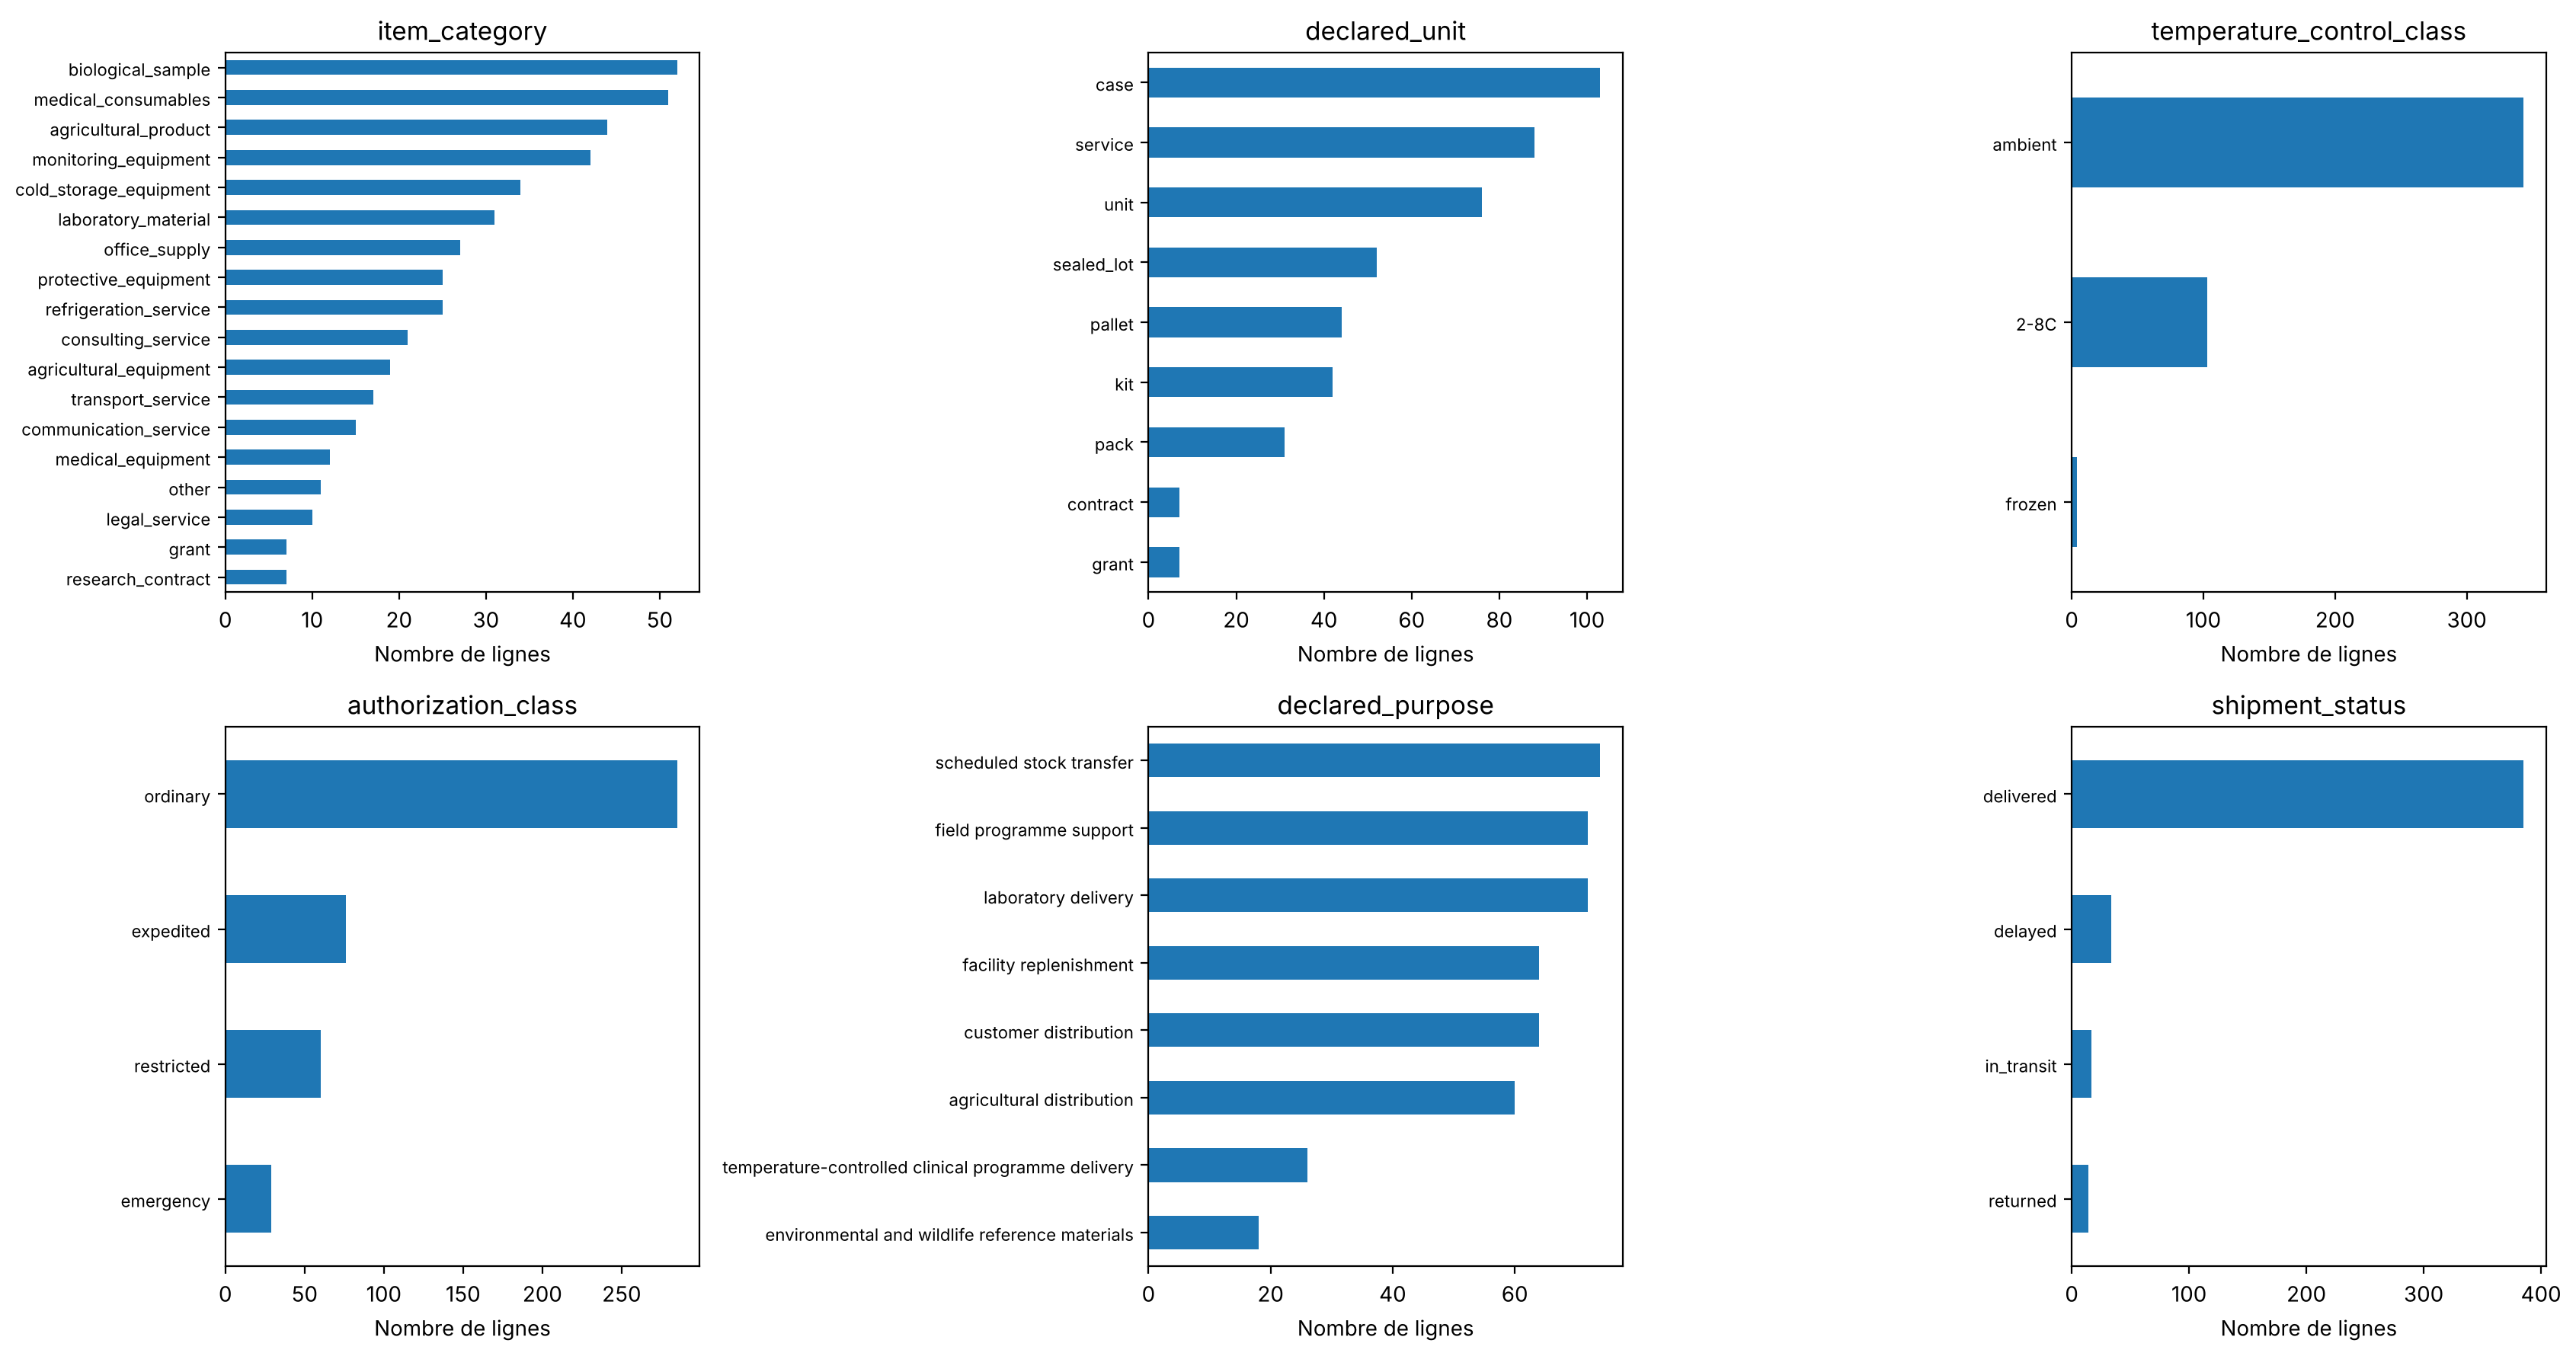

In [7]:
codes_exp = ["sender_partner_code", "receiver_partner_code", "carrier_partner_code",
             "origin_facility_code", "destination_facility_code"]
categories_exp = ["item_category", "declared_unit", "temperature_control_class",
                  "authorization_class", "declared_purpose", "shipment_status"]
repartitions_exp = {}
for colonnes in [codes_exp, categories_exp]:
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    for colonne, ax in zip(colonnes, axes.flat):
        limite = 5 if colonne in codes_exp else expeditions[colonne].nunique()
        repartitions_exp[colonne] = barres(expeditions, colonne, limite=limite, ax=ax)
        ax.tick_params(axis="y", labelsize=8)
    for ax in axes.flat[len(colonnes):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


Meridian (`BP-30078`) est l'expéditeur le plus fréquent : 90 lignes, soit 20 %. Le siège `FCL-1011` est le départ le plus fréquent (100 lignes) et `FCL-1007` la destination la plus fréquente (56). Ce sont des nombres d'expéditions, pas des quantités transportées.

Les unités diffèrent : caisses, lots, prestations, etc. Nous séparons donc catégorie et unité dans les statistiques de quantité. Le statut `delivered` concerne 385 lignes.

### Quantités atypiques et durées

Nous appliquons l'IQR aux 18 groupes catégorie–unité. Pour limiter l'affichage, les graphiques de quantité montrent les deux groupes signalés. Les statistiques de tous les groupes restent dans `bilan_quantites_exp`. La durée est l'écart entre les horaires enregistrés.


Quantités signalées par l'IQR : 5
Durées calculables : 433
Durées négatives : 0


,shipment_number,item_category,declared_quantity,declared_unit,origin_facility_code,destination_facility_code
34,SHP-2016-00017,biological_sample,17,sealed_lot,FCL-1002,FCL-1028
144,SHP-2019-00044,biological_sample,18,sealed_lot,FCL-1010,FCL-1021
259,SHP-2022-00025,office_supply,2,case,FCL-1010,FCL-1022
294,SHP-2022-00060,biological_sample,18,sealed_lot,FCL-1011,FCL-1007
316,SHP-2023-00021,biological_sample,16,sealed_lot,FCL-1012,FCL-1010


count    433.00
mean      49.92
std       26.35
min        6.00
25%       26.00
50%       49.00
75%       74.00
max       95.00
Name: duree_heures, dtype: float64

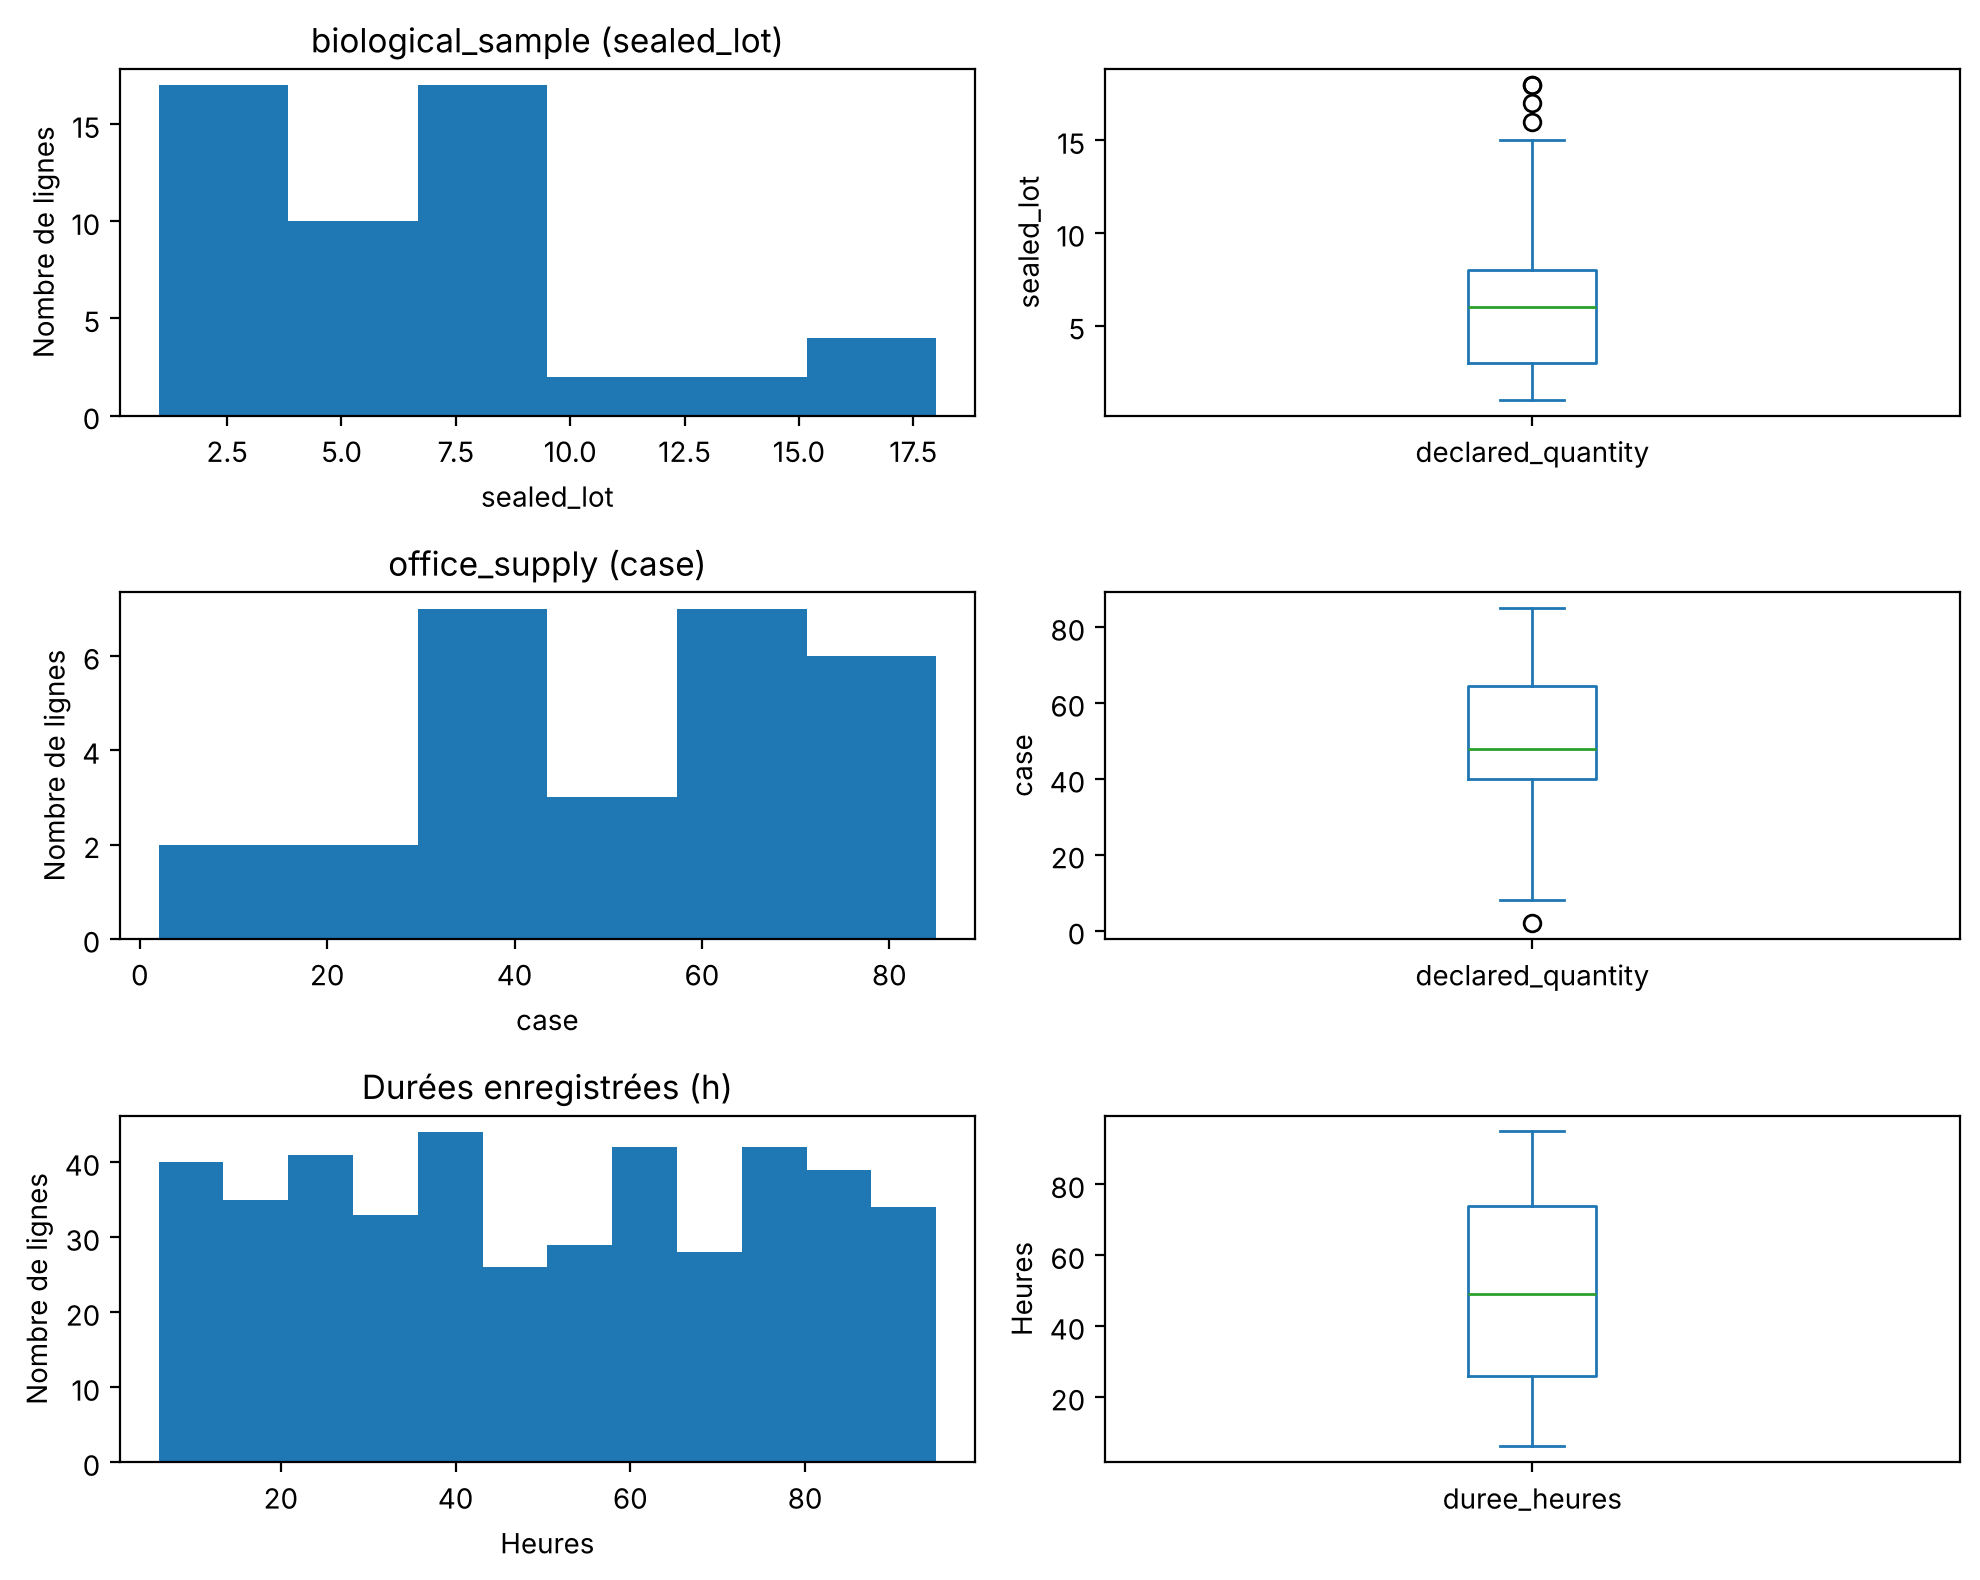

In [8]:
exp = expeditions.copy()
groupes_exp = ["item_category", "declared_unit"]
bilan_quantites_exp = exp.groupby(groupes_exp)["declared_quantity"].describe()
exp["hors_iqr"] = exp.groupby(groupes_exp)["declared_quantity"].transform(hors_iqr)
exp["duree_heures"] = (exp["arrival_time"] - exp["dispatch_time"]).dt.total_seconds() / 3600
print("Quantités signalées par l'IQR :", exp["hors_iqr"].sum())
print("Durées calculables :", exp["duree_heures"].notna().sum())
print("Durées négatives :", exp["duree_heures"].lt(0).sum())
display(exp.loc[exp["hors_iqr"], ["shipment_number", "item_category", "declared_quantity",
                                "declared_unit", "origin_facility_code", "destination_facility_code"]])
display(exp["duree_heures"].describe().round(2))

groupes_signales = exp.loc[exp["hors_iqr"], groupes_exp].drop_duplicates()
fig, axes = plt.subplots(len(groupes_signales) + 1, 2, figsize=(10, 8))
for ligne, (categorie, unite) in enumerate(groupes_signales.itertuples(index=False, name=None)):
    quantites = exp.loc[exp["item_category"].eq(categorie) & exp["declared_unit"].eq(unite), "declared_quantity"]
    quantites.plot.hist(bins=6, ax=axes[ligne, 0], title=f"{categorie} ({unite})")
    quantites.plot.box(ax=axes[ligne, 1], ylabel=unite)
    axes[ligne, 0].set_xlabel(unite)
exp["duree_heures"].plot.hist(bins=12, ax=axes[-1, 0], title="Durées enregistrées (h)")
exp["duree_heures"].plot.box(ax=axes[-1, 1], ylabel="Heures")
axes[-1, 0].set_xlabel("Heures")
for ax in axes[:, 0]:
    ax.set_ylabel("Nombre de lignes")
plt.tight_layout()
plt.show()


Quatre expéditions biologiques ont une quantité de 16 à 18 lots ; une livraison de fournitures de bureau contient 2 caisses. Deux valeurs de 18 lots se superposent sur le boxplot. Leurs trajets et dates diffèrent. Toutes sont déclarées livrées. Le régime 2–8 °C concerne les quatre cas biologiques, mais aussi l'ensemble de cette catégorie : ce régime ne les distingue donc pas.

Les 433 durées calculables vont de 6 à 95 heures, avec une médiane de 49 heures. Il n'y a pas de durée négative.

### Quantité et durée : corrélations et nuages de points

Nous calculons Pearson et Spearman séparément par catégorie et unité, sur les paires renseignées. Une quantité constante ne permet pas de calculer une corrélation. Les codes et les dates brutes sont exclus de ces calculs.


,categorie,unite,n,Pearson,Spearman
0,agricultural_equipment,unit,19,0.148,0.158
1,agricultural_product,pallet,44,0.245,0.245
2,biological_sample,sealed_lot,51,-0.321,-0.322
3,cold_storage_equipment,unit,33,-0.221,-0.266
4,laboratory_material,pack,29,-0.042,-0.115
5,medical_consumables,case,49,0.056,0.094
6,medical_equipment,unit,12,-0.092,-0.030
7,monitoring_equipment,kit,41,0.046,0.039
8,office_supply,case,25,0.064,0.141
9,other,unit,10,0.475,0.407


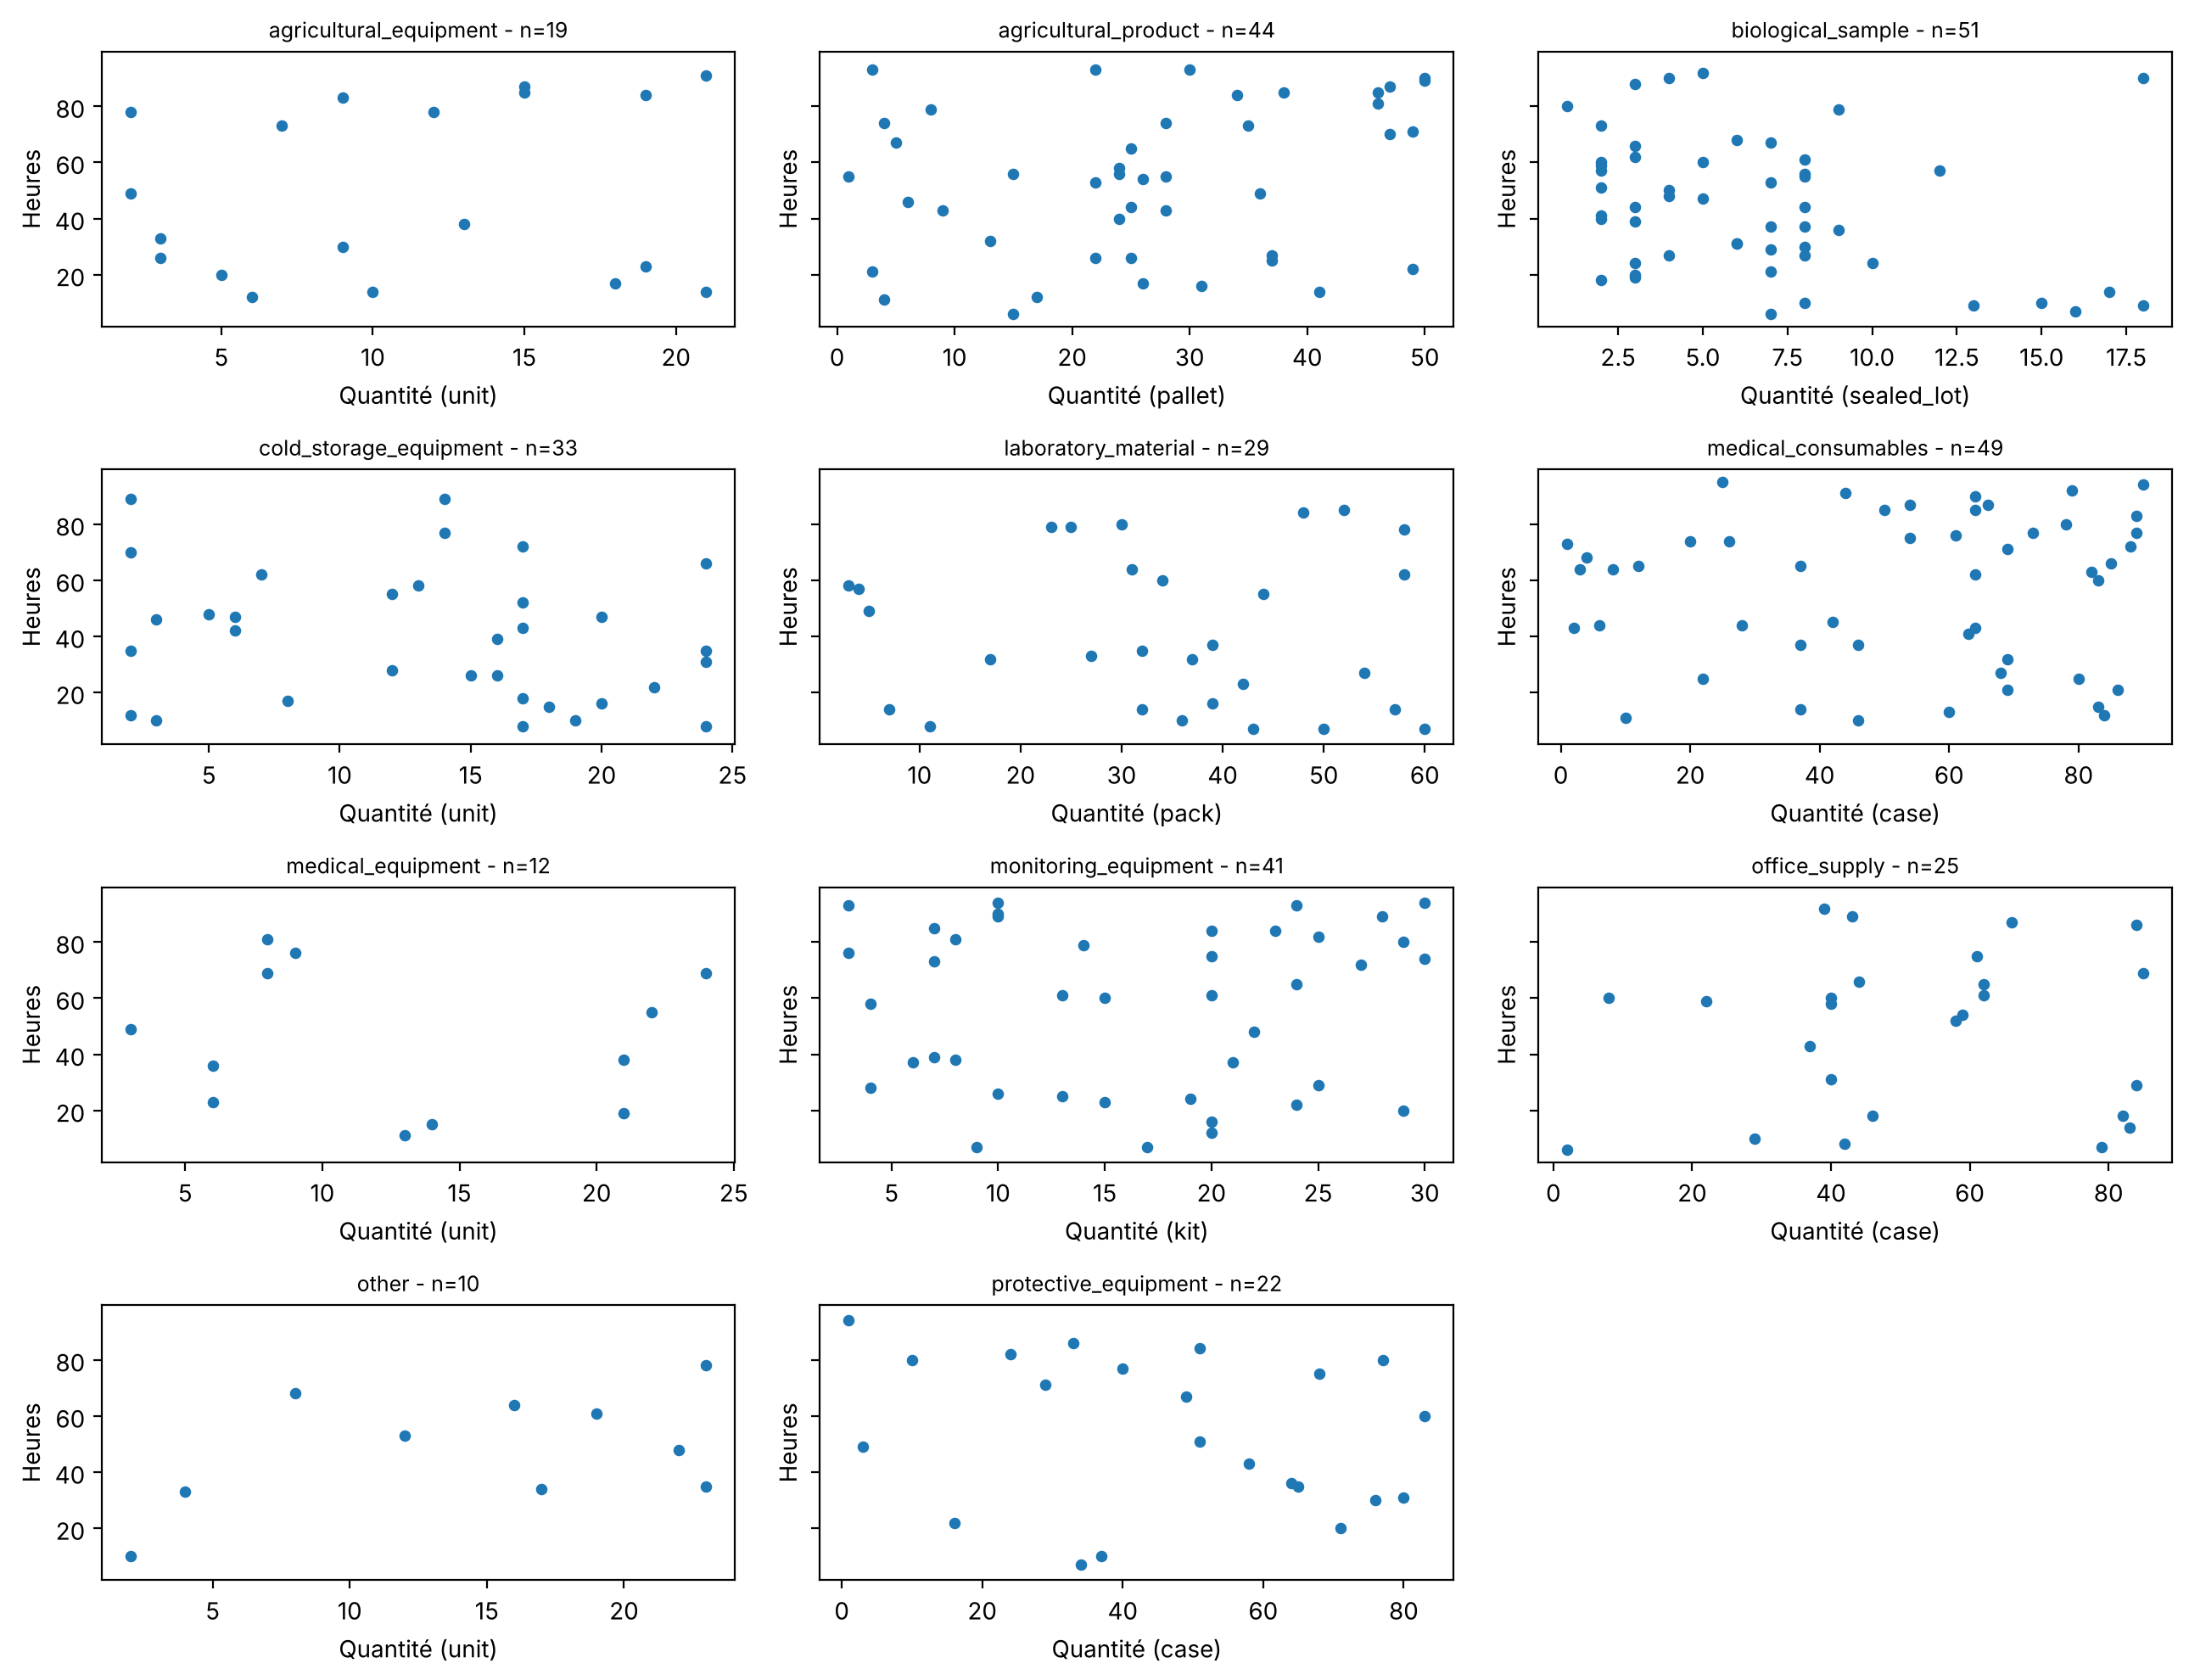

In [9]:
correlations_exp = []
for (categorie, unite), groupe in exp.groupby(groupes_exp):
    paires = groupe[["declared_quantity", "duree_heures"]].dropna()
    if len(paires) >= 3 and paires.nunique().min() > 1:
        correlations_exp.append({"categorie": categorie, "unite": unite, "n": len(paires),
            "Pearson": paires.corr().iloc[0, 1],
            "Spearman": paires.corr(method="spearman").iloc[0, 1]})
correlations_exp = pd.DataFrame(correlations_exp)
display(correlations_exp.round(3))

fig, axes = plt.subplots(4, 3, figsize=(13, 10), sharey=True)
for ax, ligne in zip(axes.flat, correlations_exp.itertuples(index=False)):
    groupe = exp[exp["item_category"].eq(ligne.categorie) & exp["declared_unit"].eq(ligne.unite)]
    ax.scatter(groupe["declared_quantity"], groupe["duree_heures"], s=15)
    ax.set_title(f"{ligne.categorie} - n={ligne.n}", fontsize=9)
    ax.set_xlabel(f"Quantité ({ligne.unite})")
    ax.set_ylabel("Heures")
for ax in axes.flat[len(correlations_exp):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


Le tableau contient 11 groupes (335 paires). Les sept groupes à quantité constante représentent 98 autres paires ; les 17 durées absentes restent exclues de ce calcul seulement. Pour les échantillons biologiques, les deux coefficients valent environ −0,32, avec une dispersion importante. Le groupe `other` a les coefficients positifs les plus élevés, mais ne comporte que 10 paires. Les trajets et les transporteurs peuvent aussi intervenir : ces corrélations ne montrent pas de causalité.


## 4. Comparer les commandes et les réceptions - CM1

Nous décrivons les quantités commandées par catégorie et unité dans `bilan_quantites_commandes`. Les prix restent dans les données, mais ne sont pas analysés ici : les devises diffèrent et nous ne disposons pas de conversion.

Nous rapprochons les réceptions avec le numéro de commande **et** le numéro de ligne. Plusieurs réceptions d'une même ligne sont additionnées après vérification des unités. Une quantité reçue à zéro signifie ici qu'aucune réception n'est enregistrée.


In [10]:
commandes = tables["purchase_order_lines"].copy()
receptions = tables["goods_receipts"]
cles_commande = ["purchase_order_number", "purchase_order_line"]
verif_unites = receptions.merge(commandes[cles_commande + ["ordered_unit"]],
    on=cles_commande, how="left", validate="many_to_one", indicator=True)
if verif_unites["_merge"].eq("left_only").any() or verif_unites["received_unit"].ne(verif_unites["ordered_unit"]).any():
    raise ValueError("Vérifier les lignes de commande et les unités.")

total_recu = receptions.groupby(cles_commande).agg(
    quantite_recue=("received_quantity", "sum"), nombre_receptions=("receipt_number", "size")
).reset_index()
commandes = commandes.merge(total_recu, on=cles_commande, how="left", validate="one_to_one")
commandes["nombre_receptions"] = commandes["nombre_receptions"].fillna(0)
commandes["quantite_recue"] = commandes["quantite_recue"].fillna(0)
commandes["ecart_quantite"] = (commandes["quantite_recue"] - commandes["ordered_quantity"]).round(2)
commandes["situation"] = "quantité égale"
commandes.loc[commandes["ecart_quantite"] < 0, "situation"] = "quantité inférieure"
commandes.loc[commandes["ecart_quantite"] > 0, "situation"] = "quantité supérieure"
commandes.loc[commandes["nombre_receptions"].eq(0), "situation"] = "sans réception enregistrée"
display(pd.crosstab(commandes["order_status"], commandes["situation"]))

situation,quantité inférieure,quantité égale,sans réception enregistrée
order_status,,,
cancelled,0,0,8
completed,65,545,0
delayed,0,0,18
pending,0,0,14


545 lignes ont une quantité reçue égale à celle commandée. 65 ont une réception partielle malgré le statut `completed`, soit 10,7 % des 610 lignes avec réception. Les 40 autres n'ont aucune réception enregistrée et sont en attente, retardées ou annulées.


### Comprendre les réceptions partielles

Nous retenons les lignes au statut `completed` dont la quantité reçue est inférieure à celle commandée. Pour illustrer l'écart, nous affichons les trois premiers cas en caisses, dans l'ordre des dates. L'analyse par fournisseur, site et article porte ensuite sur les 65 cas, toutes unités confondues : nous comptons des commandes, sans additionner leurs quantités.


In [11]:
cloturees = commandes[commandes["order_status"].eq("completed")].copy()
cloturees["partielle"] = cloturees["situation"].eq("quantité inférieure")
partielles = cloturees[cloturees["partielle"]].copy()

exemples_partiels = partielles[partielles["ordered_unit"].eq("case")].sort_values("order_date").head(3)
display(exemples_partiels[["purchase_order_number", "ordered_quantity",
                           "quantite_recue", "ordered_unit"]])


,purchase_order_number,ordered_quantity,quantite_recue,ordered_unit
28,PO-2016-00002,61,56.41,case
41,PO-2016-00015,3,2.44,case
90,PO-2018-00010,82,69.37,case


Par exemple, `PO-2016-00002` est clôturée avec 61 caisses commandées et 56,41 réceptionnées : l'écart est de 4,59 caisses.

Pour comparer les groupes, nous calculons : **nombre de cas partiels / nombre de commandes clôturées du groupe × 100**. Le tableau affiche les trois groupes ayant le plus de cas pour chaque axe, départagés par le nombre de commandes clôturées. Les bilans complets restent dans `bilans_partiels`.


In [12]:
groupes_partiels = {
    "Fournisseur": ("supplier_partner_code", partenaires.set_index("partner_code")["partner_name"]),
    "Site": ("ordering_facility_code", sites.set_index("facility_code")["facility_name"]),
    "Article": ("item_code", commandes.drop_duplicates("item_code").set_index("item_code")["item_description"])
}
bilans_partiels = {}
extraits_partiels = []
for groupe, (colonne, noms) in groupes_partiels.items():
    bilan = cloturees.groupby(colonne)["partielle"].agg(cloturees="size", partielles="sum")
    bilan["partielles_pct"] = (100 * bilan["partielles"] / bilan["cloturees"]).round(1)
    bilan["nom"] = bilan.index.map(noms)
    bilan = bilan.sort_values(["partielles", "cloturees"], ascending=False)
    bilans_partiels[groupe] = bilan
    extrait = bilan.head(3).copy()
    extrait["groupe"] = groupe
    extraits_partiels.append(extrait)

resume_partiels = pd.concat(extraits_partiels).reset_index(drop=True)
display(resume_partiels[["groupe", "nom", "cloturees", "partielles", "partielles_pct"]])


,groupe,nom,cloturees,partielles,partielles_pct
0,Fournisseur,Meridian BioLogistics,109,11,10.1
1,Fournisseur,Nordhaven Refrigeration Works,11,3,27.3
2,Fournisseur,Kintara Field Equipment Cooperative,10,3,30.0
3,Site,Meridian Valenne Headquarters,133,15,11.3
4,Site,Asterion Avelora Executive Clinic,76,7,9.2
5,Site,Asterion Central Clinical Campus,61,7,11.5
6,Article,Sterile administration supplies,38,6,15.8
7,Article,Regional refrigerated transport service,30,6,20.0
8,Article,Office supply case,35,5,14.3


Les 65 cas concernent 34 fournisseurs, 18 sites et 25 articles. Meridian a le plus de cas (11), mais aussi 109 commandes clôturées : sa proportion est de 10,1 %, contre 10,7 % dans l'ensemble. Son nombre de cas ne suffit donc pas à le distinguer des autres fournisseurs.

Les écarts restent à expliquer : le dictionnaire ne précise pas si une commande partiellement réceptionnée peut être clôturée.


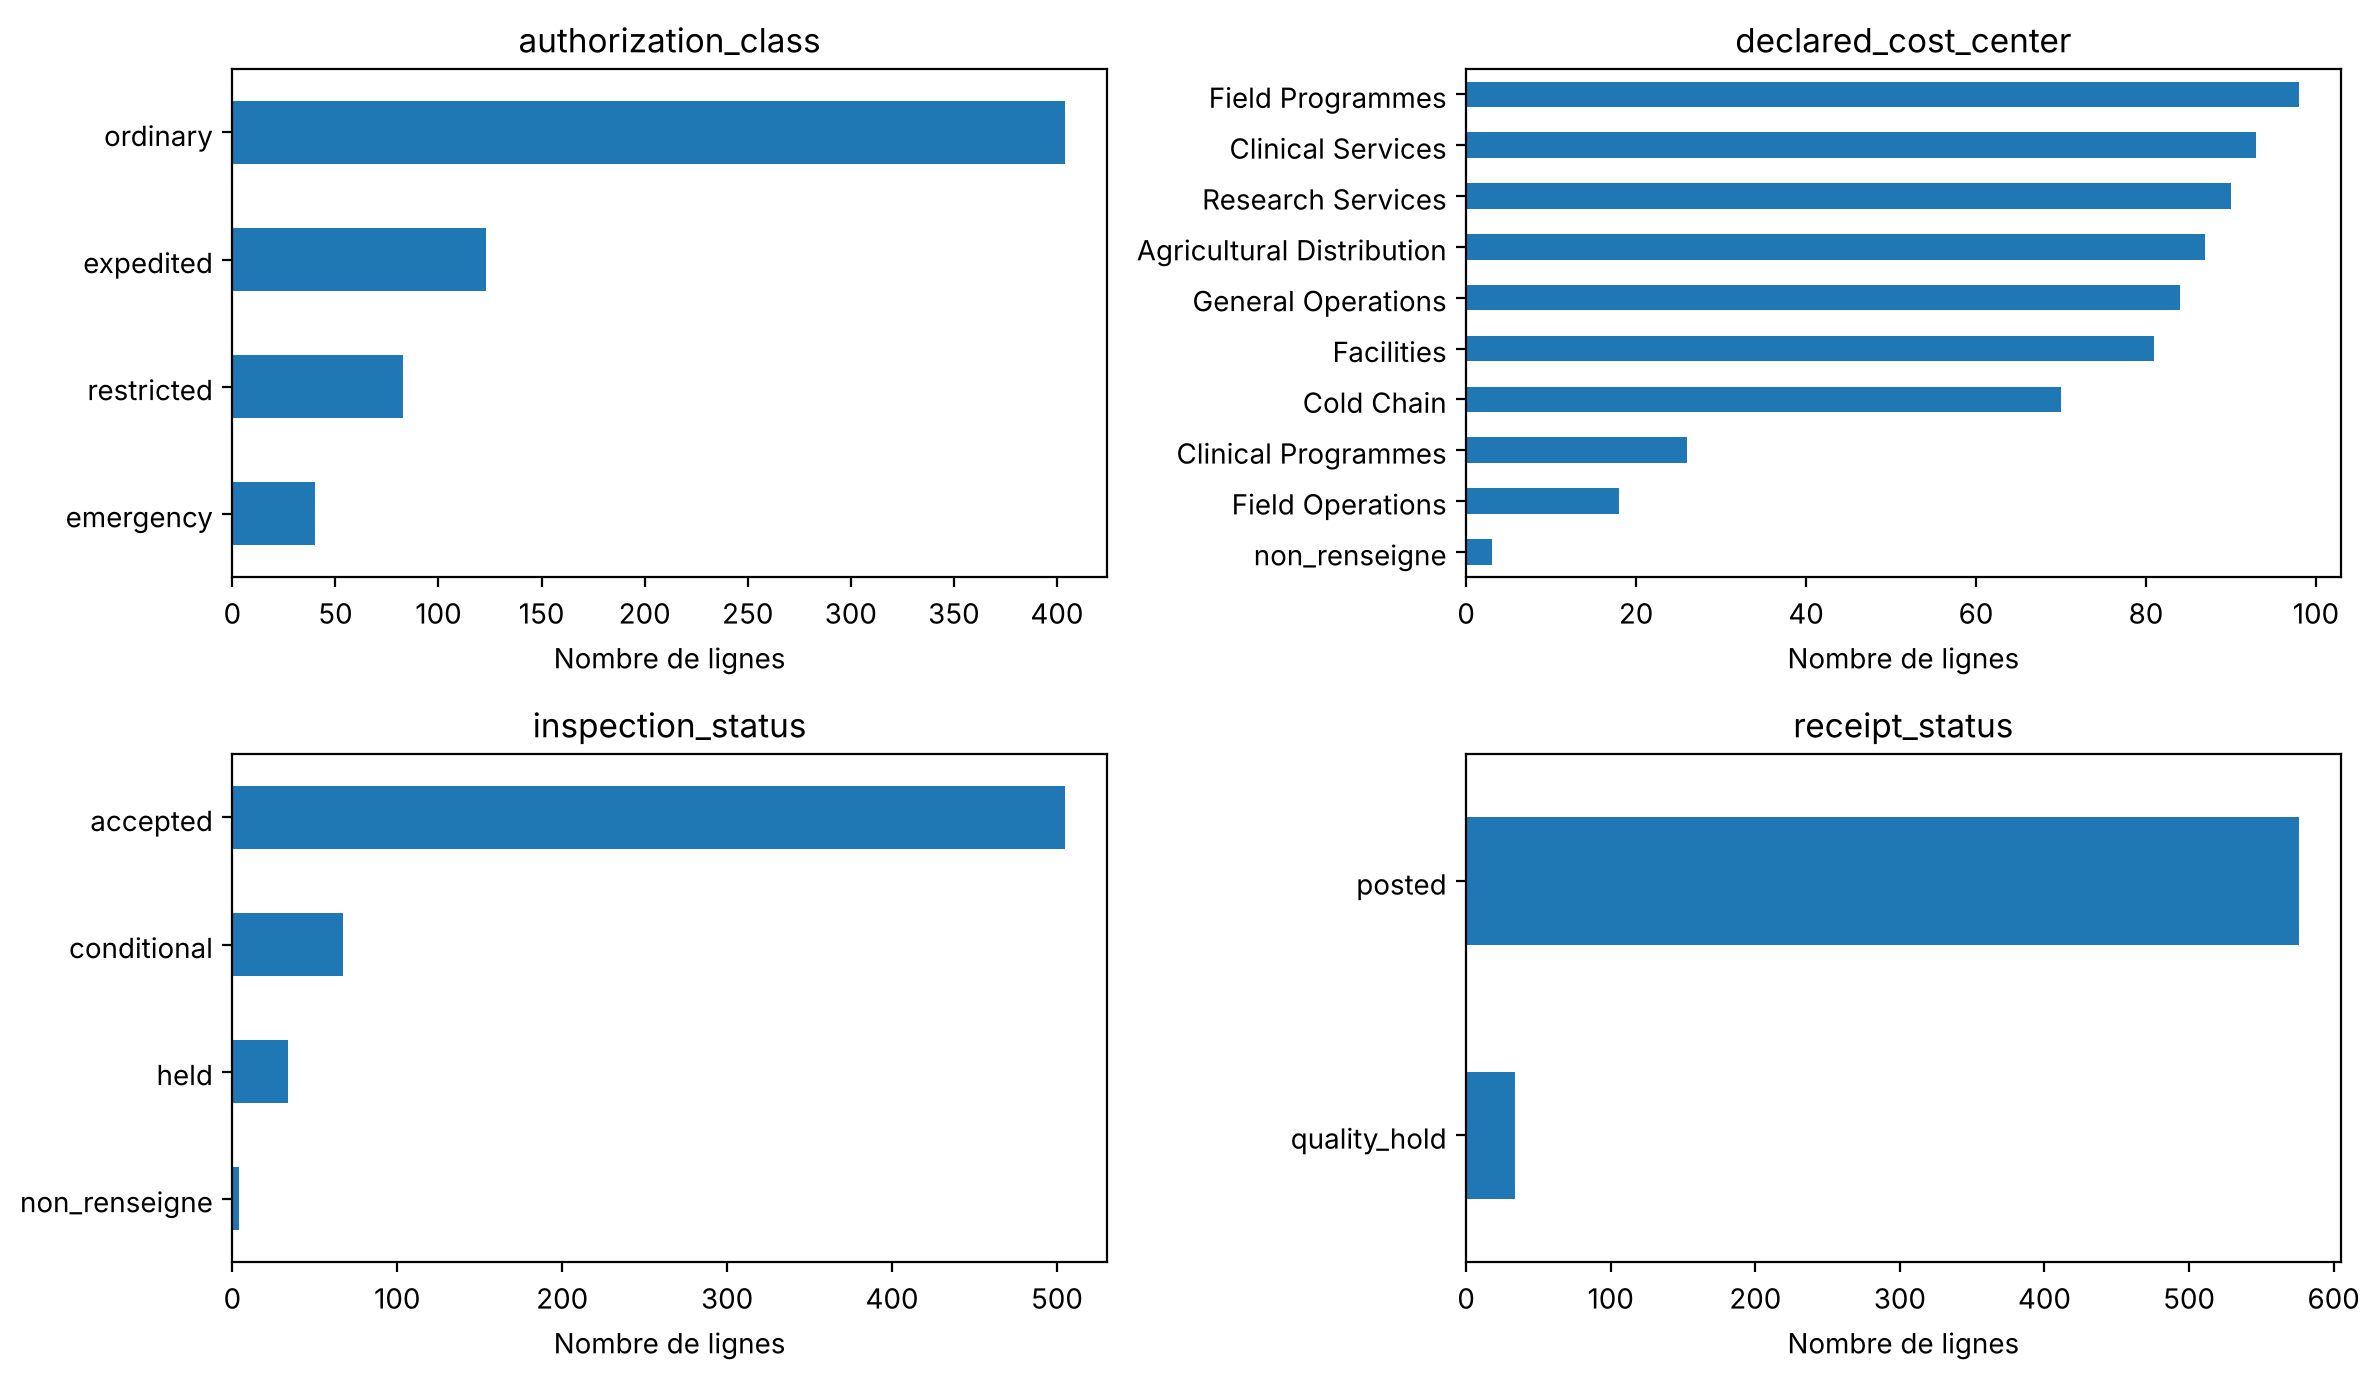

In [13]:
bilan_quantites_commandes = commandes.groupby(
    ["item_category", "ordered_unit"]
)["ordered_quantity"].describe()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for colonne, ax in zip(["authorization_class", "declared_cost_center"], axes[0]):
    barres(commandes, colonne, ax=ax)
for colonne, ax in zip(["inspection_status", "receipt_status"], axes[1]):
    barres(receptions, colonne, ax=ax)
plt.tight_layout()
plt.show()


Les autorisations de commande sont majoritairement ordinaires. Pour les réceptions, l'inspection est acceptée dans 505 cas, conditionnelle dans 67 et en attente dans 34 ; quatre statuts manquent. Le statut `posted` décrit la comptabilisation et ne remplace pas le résultat de l'inspection.


In [14]:
rec = receptions.merge(
    commandes[cles_commande + ["order_date", "requested_delivery_date"]],
    on=cles_commande, how="left", validate="many_to_one"
)
rec["retard_jours"] = (rec["receipt_date"] - rec["requested_delivery_date"]).dt.days
display(rec["retard_jours"].describe().round(2))
print("Réceptions après la date demandée :", rec["retard_jours"].gt(0).sum(), "sur", len(rec))
display(rec.nsmallest(1, "retard_jours")[["receipt_number", "receipt_date", "requested_delivery_date", "retard_jours"]])

count    610.00
mean       1.97
std        3.29
min      -22.00
25%       -1.00
50%        2.00
75%        5.00
max        7.00
Name: retard_jours, dtype: float64

Réceptions après la date demandée : 386 sur 610


,receipt_number,receipt_date,requested_delivery_date,retard_jours
609,RCV-2025-00610,2025-06-30,2025-07-22,-22


386 réceptions sont enregistrées après la date demandée, avec un retard maximal de 7 jours. Une réception est enregistrée 22 jours avant cette date ; les champs disponibles n'en expliquent pas la raison.


## 5. Examiner les ajustements - CM1

`adjustment_quantity` est une quantité signée : une valeur négative représente un retrait. Les unités diffèrent selon les articles. Nous décrivons donc les quantités par catégorie et unité, sans calculer une moyenne globale de toutes les lignes.


,,count,mean,std,min,25%,50%,75%,max
item_category,unit,,,,,,,,
agricultural_product,pallet,19.0,-0.45,4.22,-7.91,-3.30,1.00,2.42,7.24
biological_sample,sealed_lot,36.0,-1.36,4.07,-7.25,-3.65,-2.40,1.00,7.45
medical_consumables,case,51.0,-1.55,2.72,-7.88,-2.56,-2.07,-1.39,7.41
monitoring_equipment,kit,20.0,1.45,4.72,-5.10,-3.32,1.00,6.24,7.74
protective_equipment,case,14.0,1.70,4.79,-7.29,-1.00,2.11,5.92,7.87


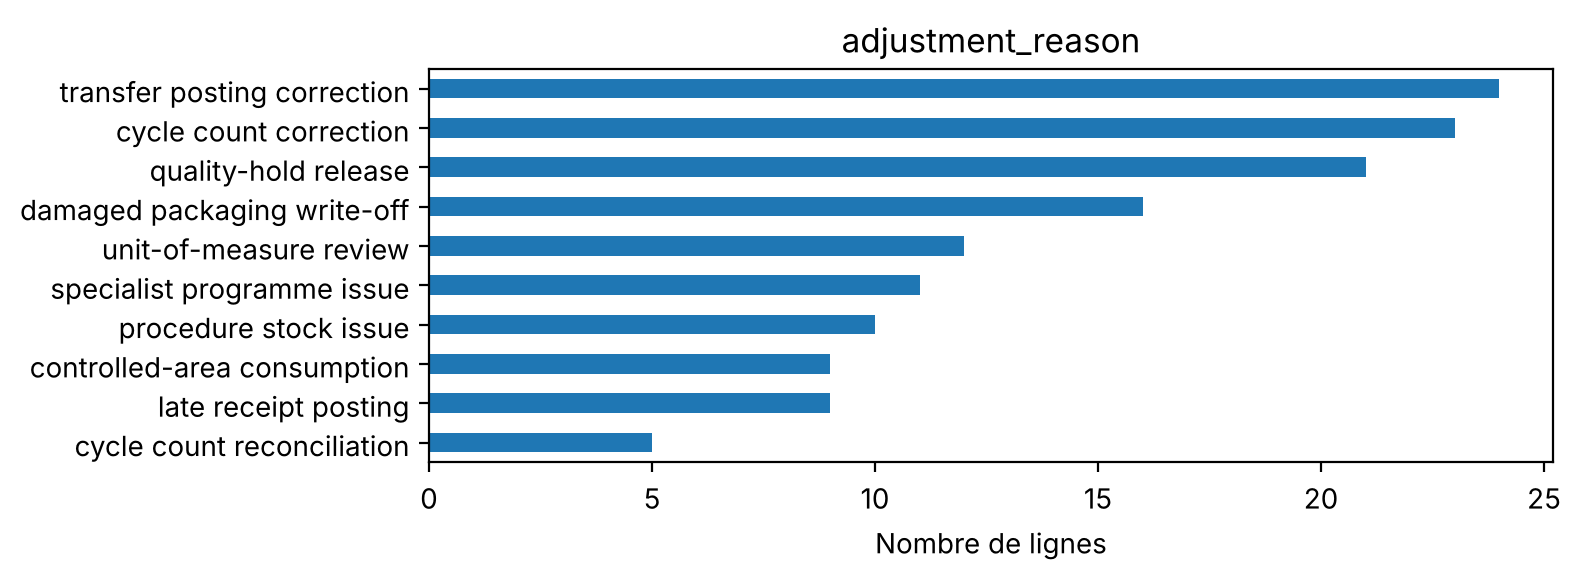

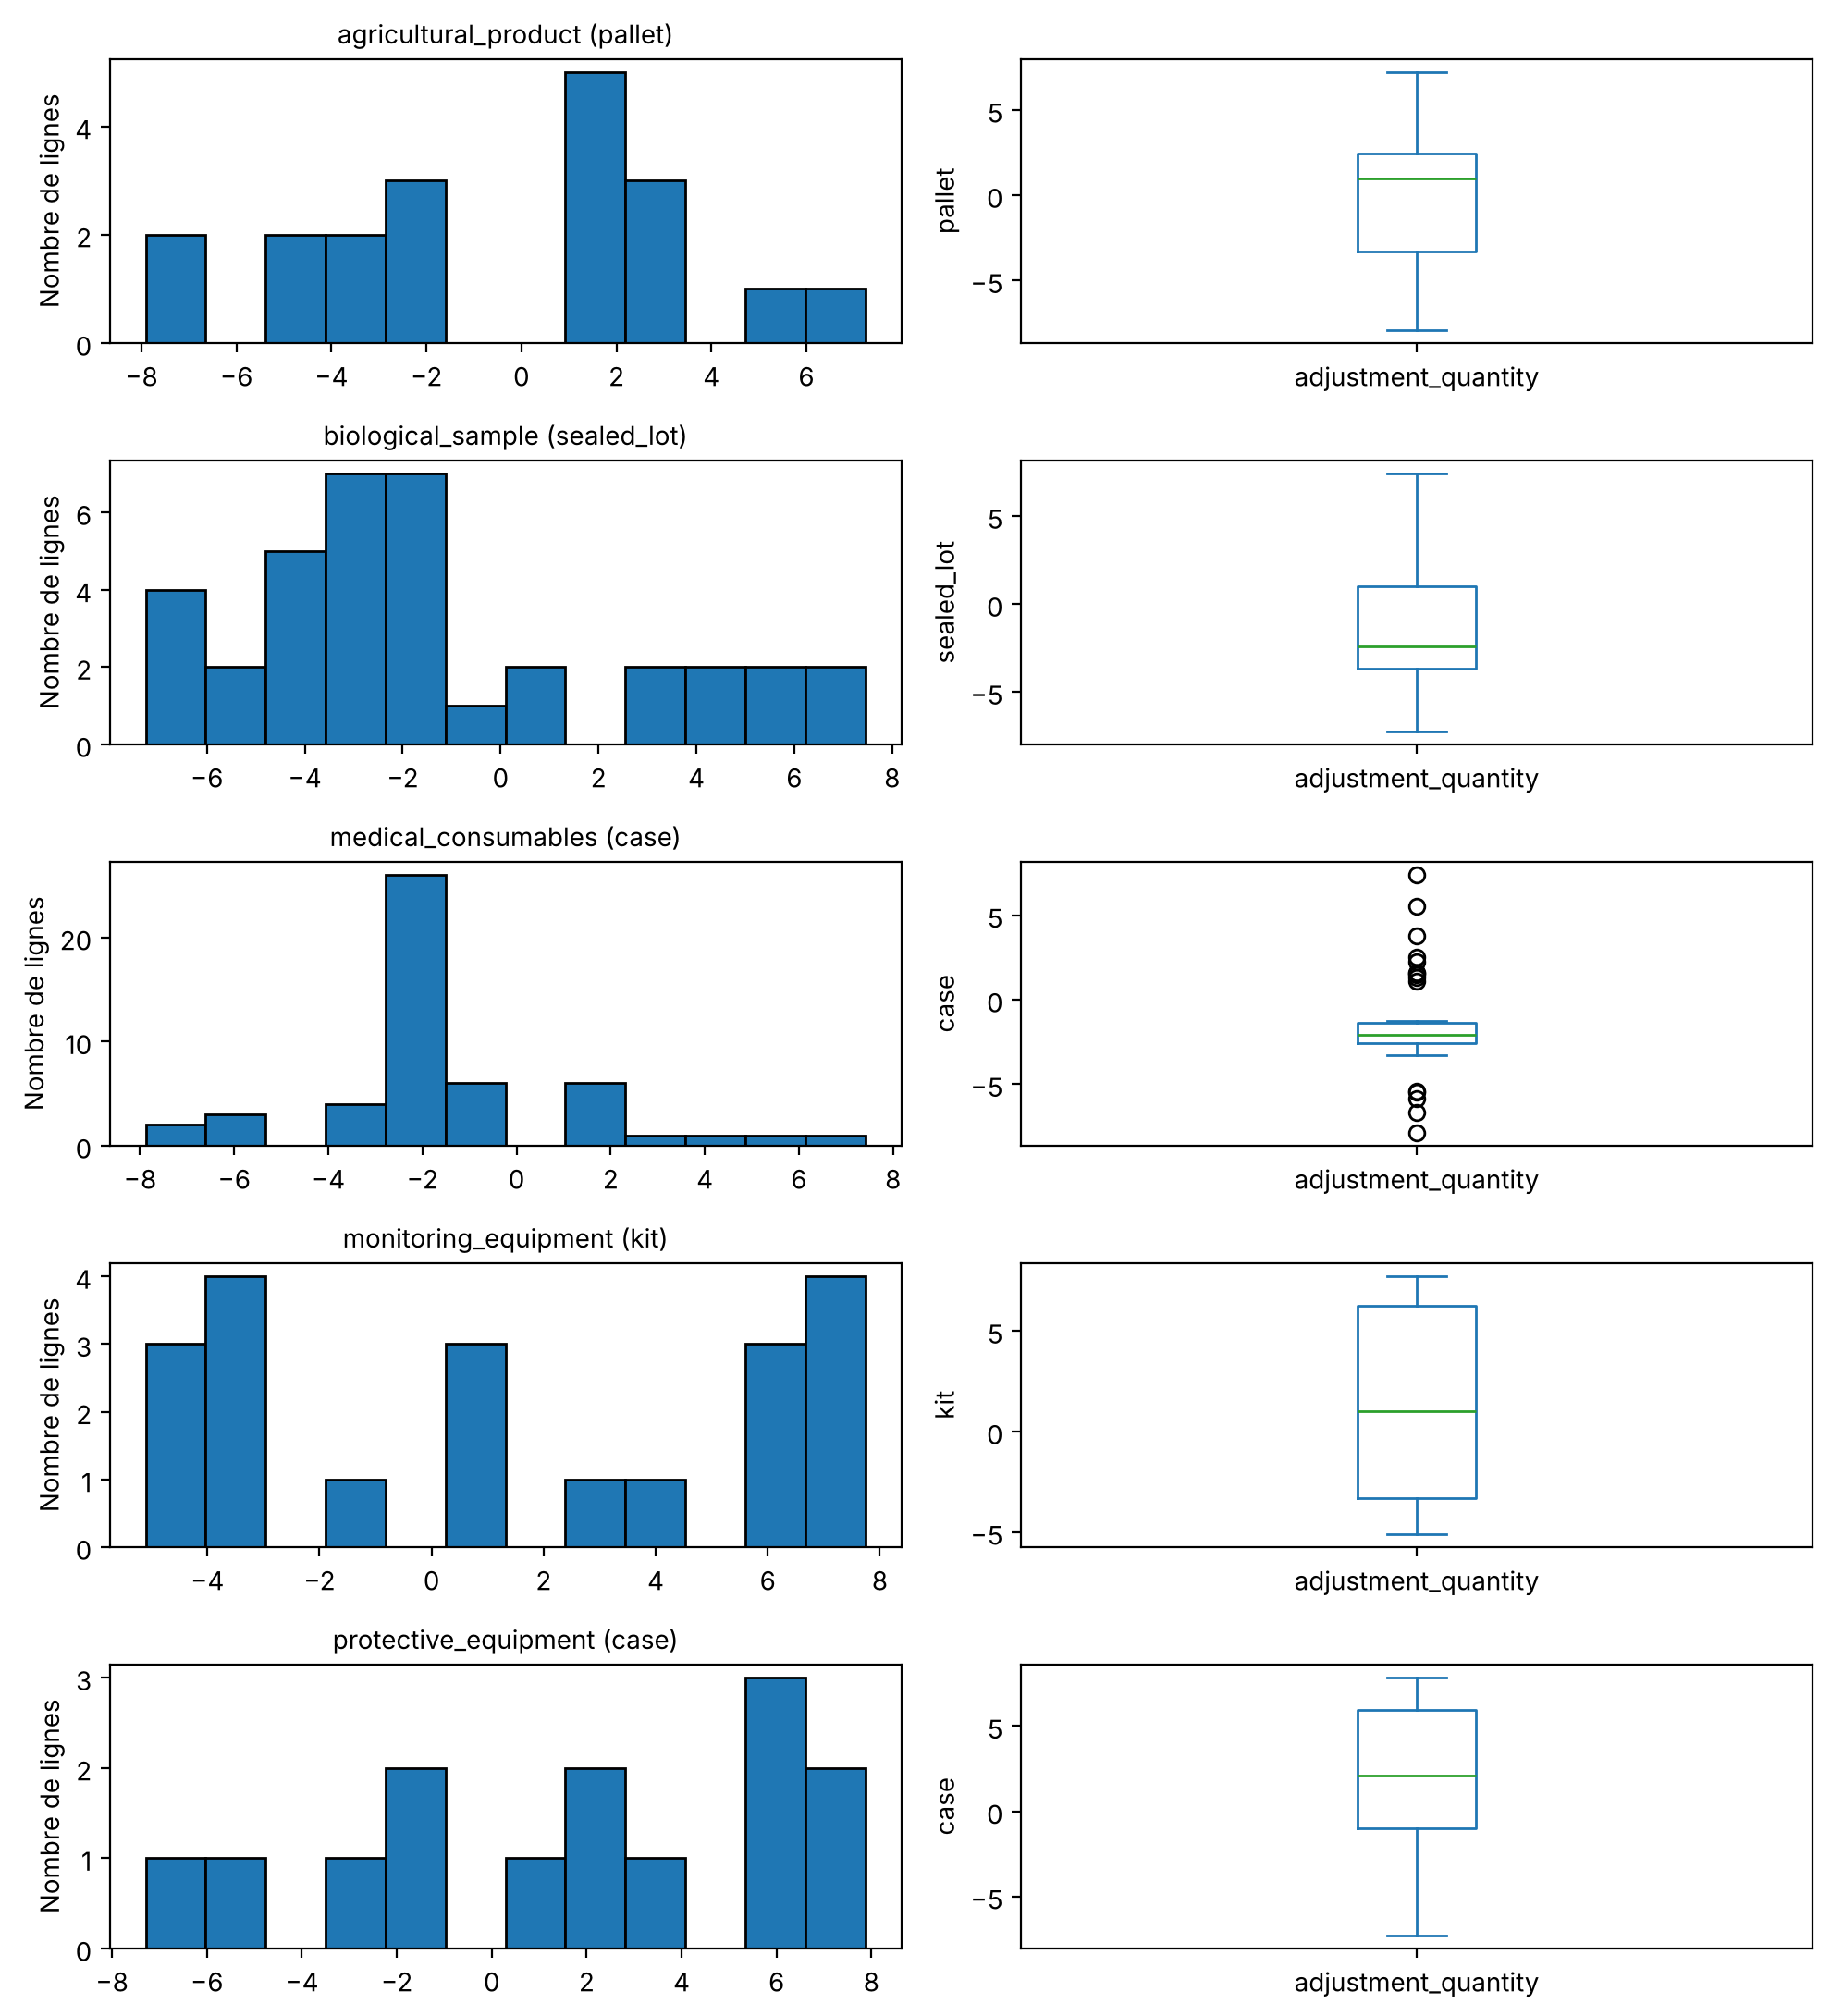

In [15]:
bilan_ajustements = ajustements.groupby(
    ["item_category", "unit"]
)["adjustment_quantity"].describe()
display(bilan_ajustements.round(2))
motifs = barres(ajustements, "adjustment_reason")

distributions_par_groupe(ajustements, "adjustment_quantity")

Nous isolons trois motifs d'usage de stock : `controlled-area consumption`, `procedure stock issue` et `specialist programme issue`. Nous regardons les articles, sites et références concernés.


In [16]:
motifs_retraits = ["controlled-area consumption", "procedure stock issue",
                   "specialist programme issue"]
retraits = ajustements[ajustements["adjustment_reason"].isin(motifs_retraits)]
print("Lignes concernées :", len(retraits), "sur", len(ajustements))
display(retraits.groupby(["item_category", "unit"]).size().to_frame("lignes"))
display(pd.crosstab(retraits["adjustment_reason"], retraits["facility_code"]))
print("Somme des ajustements :", round(retraits["adjustment_quantity"].sum(), 2))
print("Sans référence de réception ni d'expédition :",
      (retraits["related_receipt_number"].isna()
       & retraits["related_shipment_number"].isna()).sum())

Lignes concernées : 30 sur 140


,,lignes
item_category,unit,
medical_consumables,case,30


facility_code,FCL-1007,FCL-1010
adjustment_reason,,
controlled-area consumption,5,4
procedure stock issue,3,7
specialist programme issue,6,5


Somme des ajustements : -62.9
Sans référence de réception ni d'expédition : 30


Ces motifs regroupent 30 ajustements, tous négatifs, pour un total de −62,9 caisses de consommables médicaux. Ils concernent `FCL-1007` et `FCL-1010`, deux sites exploités par Asterion. Aucun ne mentionne de réception ou d'expédition, ce qui empêche de les rattacher directement à une livraison précise.


## 6. Examiner les bilans de stock - CM1

Nous calculons une clôture à partir des champs disponibles :

`clôture calculée = ouverture + reçu − sorties − usage interne − déchets`

L'écart est la clôture enregistrée moins cette clôture calculée.


In [17]:
variables_stock = ["opening_stock", "received_quantity", "outgoing_quantity",
                   "documented_internal_use", "documented_waste", "closing_stock"]
stocks["disponible"] = stocks["opening_stock"] + stocks["received_quantity"]
stocks["sorties_totales"] = (stocks["outgoing_quantity"]
                            + stocks["documented_internal_use"] + stocks["documented_waste"])
stocks["ecart"] = (stocks["closing_stock"] - stocks["disponible"]
                    + stocks["sorties_totales"]).round(2)
stocks["sorties_superieures"] = stocks["sorties_totales"] > stocks["disponible"] + 0.05

print("Bilans :", len(stocks))
print("Sorties supérieures à ouverture + reçu :", stocks["sorties_superieures"].sum())
display(stocks.groupby(["item_category", "unit"])["ecart"].describe().round(2))

Bilans : 500
Sorties supérieures à ouverture + reçu : 39


,,count,mean,std,min,25%,50%,75%,max
item_category,unit,,,,,,,,
agricultural_product,pallet,100.0,0.83,4.16,-10.10,-0.70,0.48,1.90,34.15
biological_sample,sealed_lot,100.0,-0.92,5.20,-21.80,-2.23,0.28,2.05,8.64
medical_consumables,case,100.0,-0.33,4.46,-17.76,-1.51,-0.34,1.84,24.17
monitoring_equipment,kit,100.0,-0.29,3.31,-17.23,-1.07,0.15,1.08,7.69
protective_equipment,case,100.0,0.60,4.86,-9.75,-1.06,0.08,1.38,44.37


La tolérance de 0,05 écarte les petits écarts d'arrondi.

Dans 39 bilans, les sorties totales renseignées dépassent l'ouverture et les réceptions renseignées. Nous vérifions ensuite les dates pour comparer la clôture d'un mois à l'ouverture du suivant.


In [18]:
cles_serie = ["facility_code", "item_category", "unit"]
suivi = stocks.sort_values(cles_serie + ["reporting_month"]).copy()
suivi["numero_mois"] = suivi["reporting_month"].dt.year * 12 + suivi["reporting_month"].dt.month
suivi["mois_precedent"] = suivi.groupby(cles_serie)["numero_mois"].shift()
suivi["cloture_precedente"] = suivi.groupby(cles_serie)["closing_stock"].shift()
consecutifs = (suivi["numero_mois"] - suivi["mois_precedent"]).eq(1)
non_consecutifs = suivi["mois_precedent"].notna() & ~consecutifs
ruptures = consecutifs & (suivi["opening_stock"] - suivi["cloture_precedente"]).abs().gt(0.05)

print("Comparaisons entre mois consécutifs :", consecutifs.sum())
print("Ruptures observées sur ces comparaisons :", ruptures.sum())
print("Passages entre observations non consécutives :", non_consecutifs.sum())

Comparaisons entre mois consécutifs : 50
Ruptures observées sur ces comparaisons : 0
Passages entre observations non consécutives : 425


Les 50 passages entre mois consécutifs ne montrent pas de rupture avec cette tolérance. Les 425 autres passages sont séparés par des mois non représentés : l'historique est incomplet.

Nous observons ensuite la distribution des écarts par catégorie et unité.


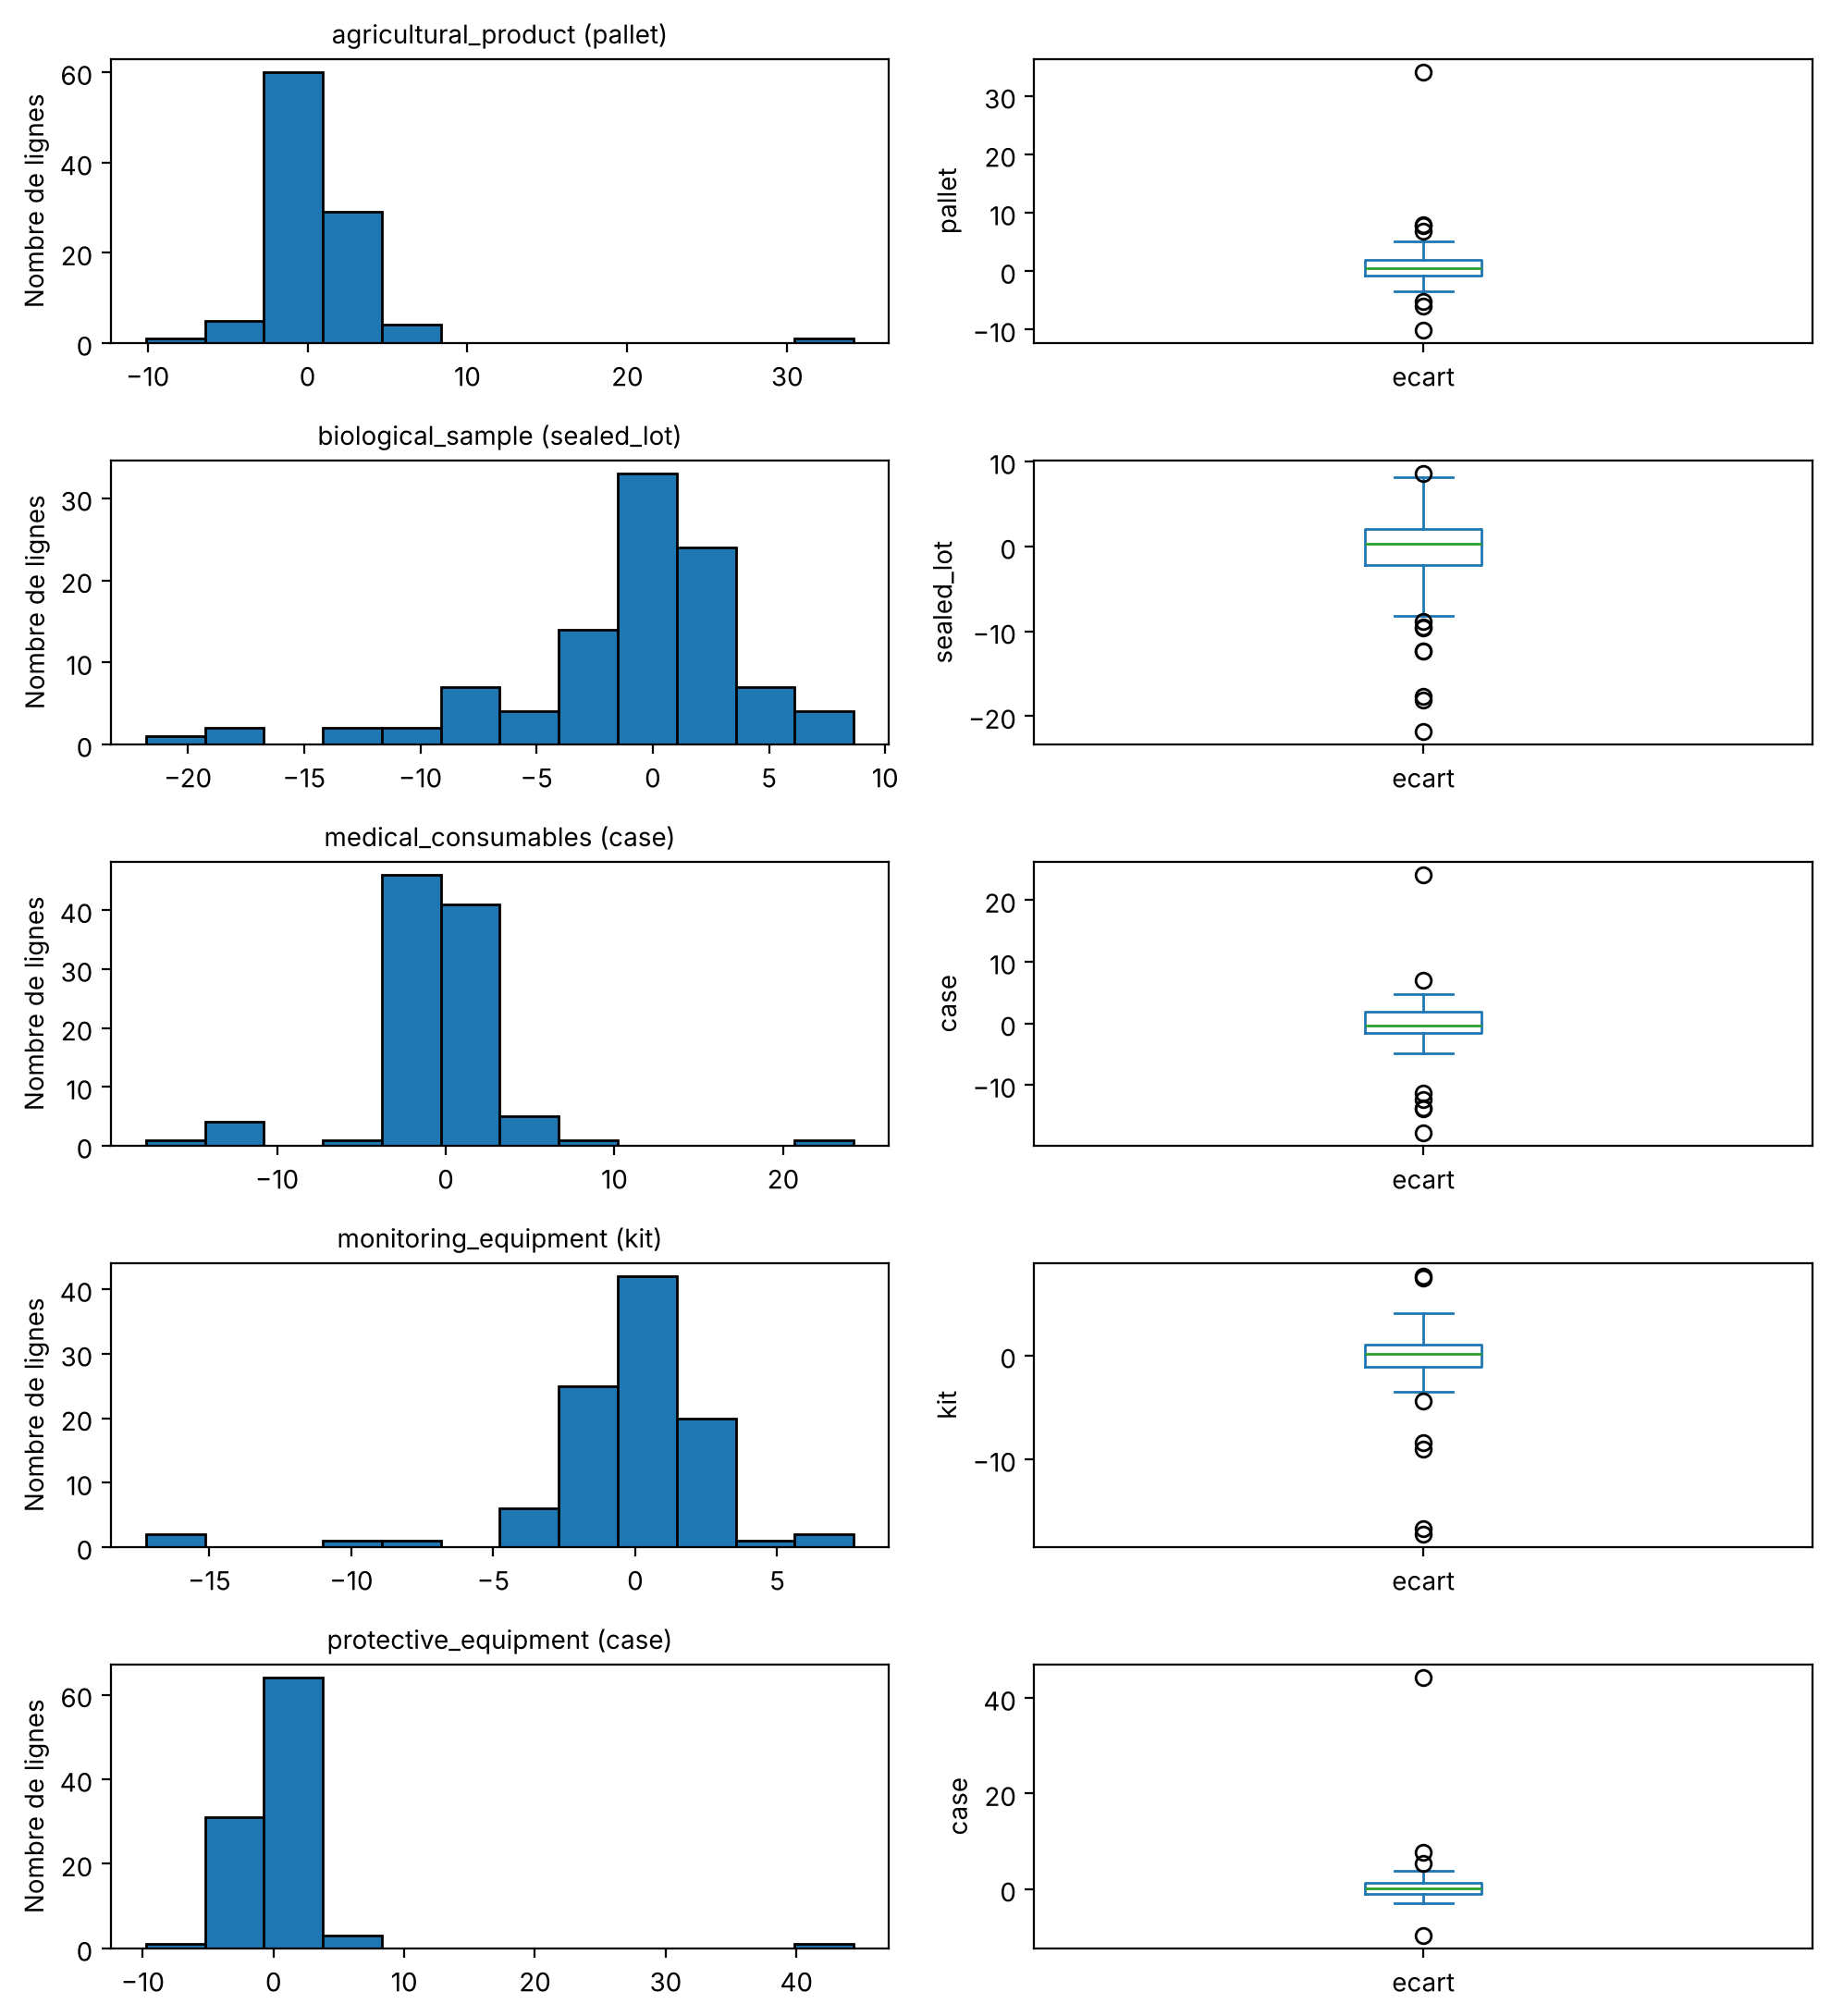

In [19]:
distributions_par_groupe(stocks, "ecart")


## 7. Comparer les profils moyens de cinq sites - CM2

Nous reprenons les consommables médicaux en caisses pour comparer des quantités de même nature. Une ligne du tableau représente maintenant **un site**, décrit par la moyenne de ses 20 observations. Les cinq sites couvrent la même période, mais les mois ne sont pas tous présents. Les moyennes résument donc les observations disponibles et masquent les variations entre mois.

Nous standardisons les cinq variables avant la comparaison. L'ACP donne un dessin en deux dimensions ; le regroupement de Ward utilise les cinq variables standardisées et la distance euclidienne. Ward est notre choix de regroupement hiérarchique du CM2 ; nous lisons le dendrogramme sans imposer un nombre de groupes.


,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
facility_code,,,,,
FCL-1010,33.23,2.94,14.07,4.32,167.62
FCL-1019,9.06,1.70,4.67,1.71,71.07
FCL-1020,3.25,3.99,1.46,0.76,21.09
FCL-1024,3.86,2.02,2.16,0.68,28.41
FCL-1027,3.76,1.81,2.83,0.82,28.59


Variance expliquée par les deux axes (%) : [80.02 19.75]


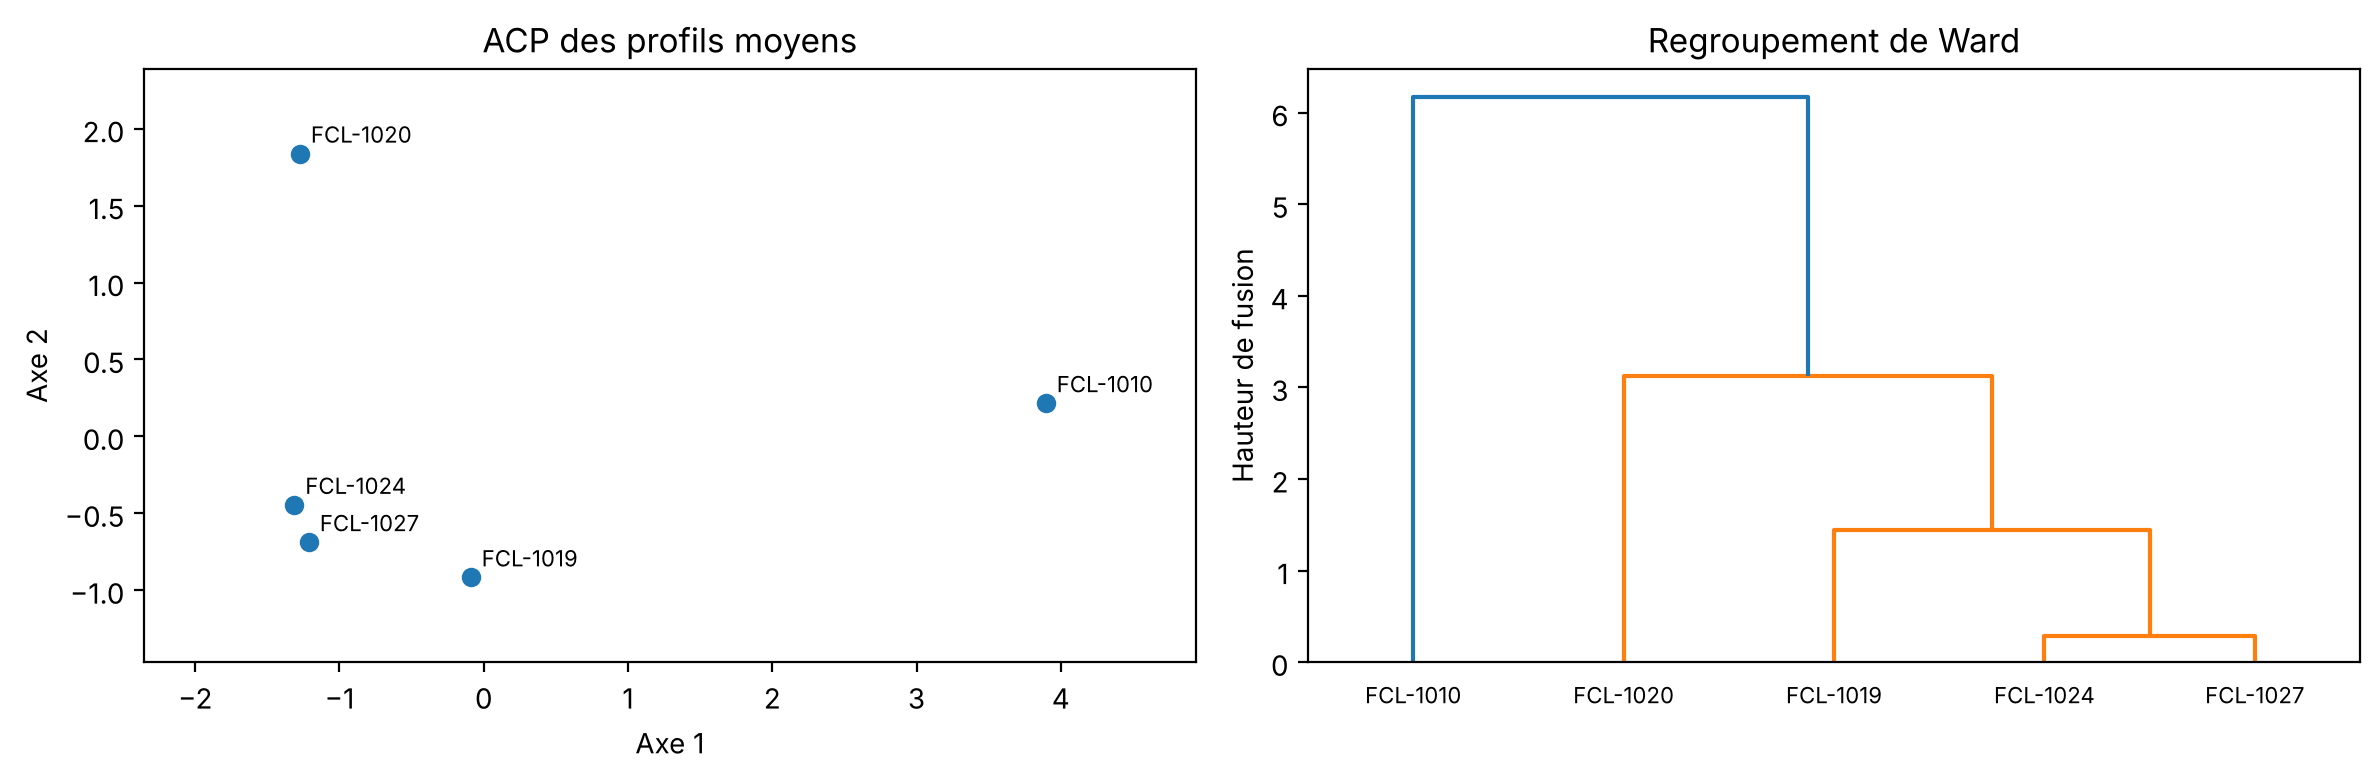

In [20]:
stocks_medicaux = stocks[stocks["item_category"].eq("medical_consumables") & stocks["unit"].eq("case")]
variables_sites = ["received_quantity", "outgoing_quantity", "documented_internal_use",
                   "documented_waste", "closing_stock"]
profils_sites = stocks_medicaux.groupby("facility_code")[variables_sites].mean()
display(profils_sites.round(2))
X_sites = StandardScaler().fit_transform(profils_sites)
pca_sites = PCA(n_components=2)
coordonnees_sites = pca_sites.fit_transform(X_sites)
liaisons_sites = linkage(X_sites, method="ward", metric="euclidean")
print("Variance expliquée par les deux axes (%) :",
      (pca_sites.explained_variance_ratio_ * 100).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(coordonnees_sites[:, 0], coordonnees_sites[:, 1])
axes[0].margins(0.2)
for nom, (x, y) in zip(profils_sites.index, coordonnees_sites):
    axes[0].annotate(nom, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[0].set(xlabel="Axe 1", ylabel="Axe 2", title="ACP des profils moyens")
dendrogram(liaisons_sites, labels=profils_sites.index, ax=axes[1])
axes[1].set(title="Regroupement de Ward", ylabel="Hauteur de fusion")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()


Les deux axes conservent environ 99,77 % de la variance des cinq profils. `FCL-1010` présente des niveaux plus élevés sur plusieurs variables ; `FCL-1024` et `FCL-1027` sont regroupés en premier. Le faible nombre de sites limite cette comparaison.

Dans la suite, chaque point représentera un bilan mensuel avec des quantités rapportées à la taille moyenne de sa série : nous passons à 500 observations.


## 8. Comparer les bilans mensuels de stock - CM1 et CM2

Les sites ont des tailles différentes. Pour comparer leurs profils, nous divisons chaque variable par le stock disponible moyen de sa série site–catégorie–unité. Les six variables obtenues sont des rapports sans unité. Ce choix réduit l'effet de taille, mais dépend de la période observée et ne corrige pas une évolution dans le temps.

Nous examinons Pearson et Spearman sur ces variables relatives, puis nous les standardisons pour les méthodes fondées sur les distances.


pearson


,opening_stock,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
opening_stock,1.00,-0.14,-0.11,0.65,0.38,0.75
received_quantity,-0.14,1.00,0.14,0.01,0.13,0.16
outgoing_quantity,-0.11,0.14,1.00,-0.11,0.11,-0.33
documented_internal_use,0.65,0.01,-0.11,1.00,0.29,0.41
documented_waste,0.38,0.13,0.11,0.29,1.00,0.19
closing_stock,0.75,0.16,-0.33,0.41,0.19,1.00


spearman


,opening_stock,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
opening_stock,1.00,-0.17,0.00,0.58,0.34,0.76
received_quantity,-0.17,1.00,-0.04,-0.04,-0.05,0.20
outgoing_quantity,0.00,-0.04,1.00,-0.11,0.09,-0.27
documented_internal_use,0.58,-0.04,-0.11,1.00,0.21,0.40
documented_waste,0.34,-0.05,0.09,0.21,1.00,0.19
closing_stock,0.76,0.20,-0.27,0.40,0.19,1.00


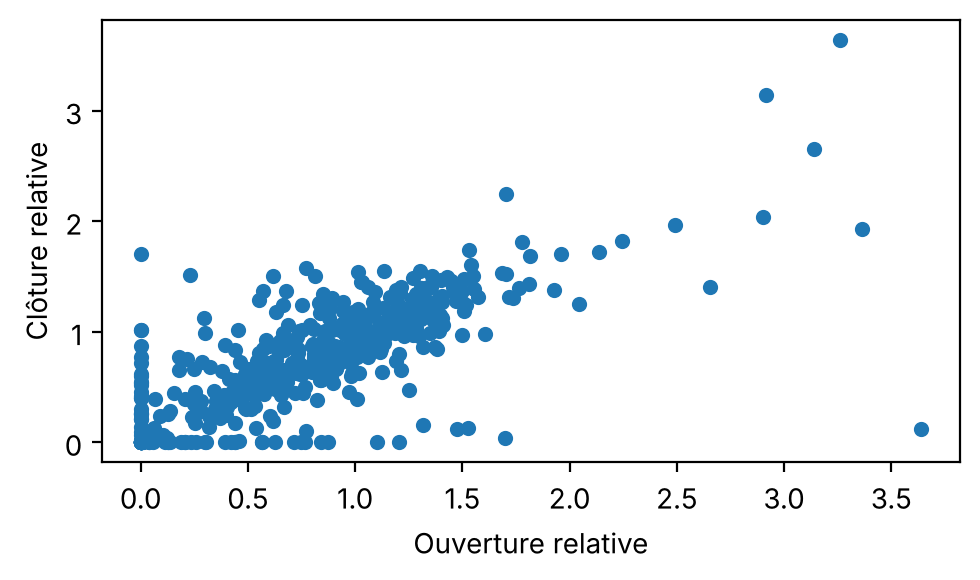

In [21]:
taille_moyenne = stocks.groupby(cles_serie)["disponible"].transform("mean")
if taille_moyenne.le(0).any():
    raise ValueError("Une taille moyenne nulle ou négative doit être examinée.")
relatives = stocks[variables_stock].div(taille_moyenne, axis=0)

for methode in ["pearson", "spearman"]:
    print(methode)
    display(relatives.corr(method=methode).round(2))

relatives.plot.scatter(x="opening_stock", y="closing_stock", figsize=(5, 3))
plt.xlabel("Ouverture relative")
plt.ylabel("Clôture relative")
plt.tight_layout()
plt.show()

Les corrélations entre les composantes du stock peuvent être influencées par leur dénominateur commun et les différences entre sites. Une faible corrélation ne suffit pas à conclure à l'indépendance.

L'ACP donne une représentation sur deux axes. La détection conserve les six variables standardisées.


Variance expliquée par les deux axes (%) : [40.7 21. ]


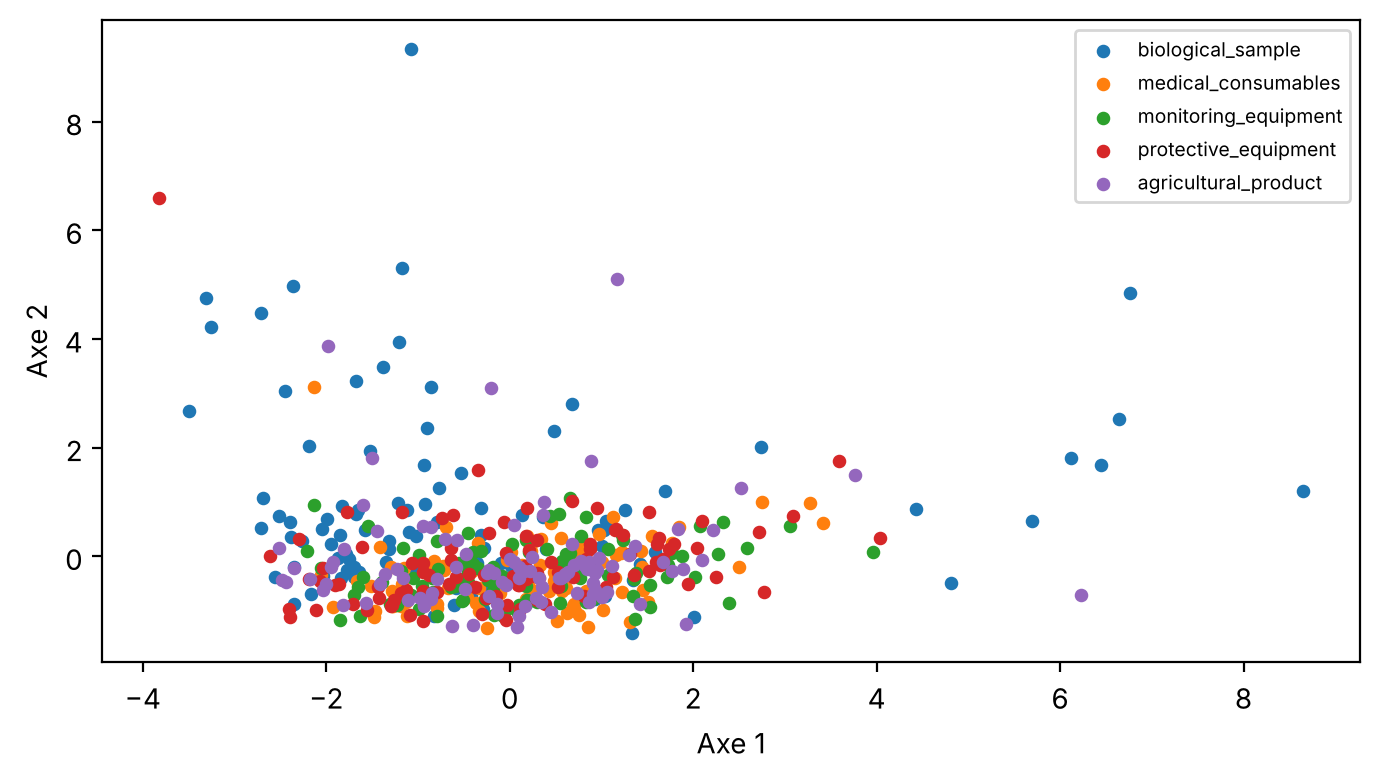

In [22]:
X_stocks = StandardScaler().fit_transform(relatives)
pca = PCA(n_components=2)
coordonnees = pca.fit_transform(X_stocks)
print("Variance expliquée par les deux axes (%) :",
      (pca.explained_variance_ratio_ * 100).round(1))

fig, ax = plt.subplots(figsize=(7, 4))
for categorie in stocks["item_category"].unique():
    selection = stocks["item_category"].eq(categorie).to_numpy()
    ax.scatter(coordonnees[selection, 0], coordonnees[selection, 1],
               label=categorie, s=15)
ax.set_xlabel("Axe 1")
ax.set_ylabel("Axe 2")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

Les deux axes expliquent 61,7 % de la variance : le dessin représente partiellement les distances entre les profils.


## 9. Repérer des écarts et profils atypiques - CM3

### 9.1. IQR et z-score sur l'écart de stock

Nous comparons chaque écart à ceux de sa catégorie et de son unité. La règle IQR signale les valeurs hors de `Q1 − 1,5 × IQR` et `Q3 + 1,5 × IQR`. Le z-score signale les valeurs à plus de trois écarts-types de la moyenne.


In [23]:
groupes_ecart = stocks.groupby(["item_category", "unit"])["ecart"]
stocks["hors_iqr"] = groupes_ecart.transform(hors_iqr)
ecart_type = groupes_ecart.transform("std")
z_score = (stocks["ecart"] - groupes_ecart.transform("mean")) / ecart_type.replace(0, np.nan)
stocks["hors_z"] = z_score.abs() > 3
display(stocks.groupby(["item_category", "unit"])[["hors_iqr", "hors_z"]].sum())


,,hors_iqr,hors_z
item_category,unit,,
agricultural_product,pallet,7,1
biological_sample,sealed_lot,9,3
medical_consumables,case,7,3
monitoring_equipment,kit,7,2
protective_equipment,case,4,1


L'IQR signale 34 bilans et le z-score 10.

### 9.2. DBSCAN et LOF sur les six variables ensemble

DBSCAN utilise la distance euclidienne sur les six variables relatives standardisées. `min_samples=5` compte le point et quatre autres observations. Nous comparons trois valeurs de `eps` avant de retenir 1,5 pour cette exploration.


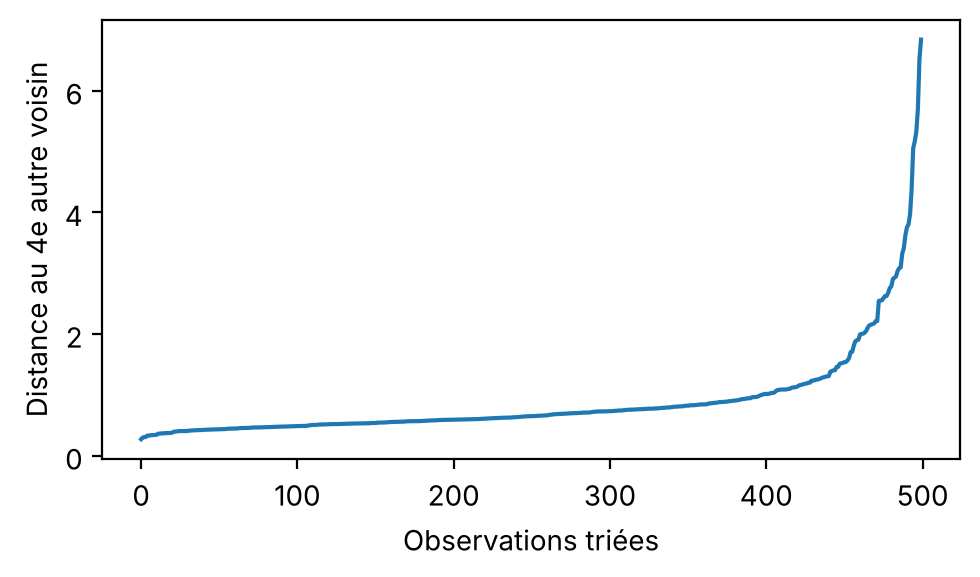

,eps,points_bruit
0,1.0,74
1,1.5,44
2,2.0,29


In [24]:
voisins = NearestNeighbors(n_neighbors=5).fit(X_stocks)
distances = voisins.kneighbors(X_stocks)[0][:, -1]
plt.figure(figsize=(5, 3))
plt.plot(np.sort(distances))
plt.xlabel("Observations triées")
plt.ylabel("Distance au 4e autre voisin")
plt.tight_layout()
plt.show()

essais_dbscan = []
for epsilon in [1.0, 1.5, 2.0]:
    labels = DBSCAN(eps=epsilon, min_samples=5).fit_predict(X_stocks)
    essais_dbscan.append({"eps": epsilon, "points_bruit": (labels == -1).sum()})
display(pd.DataFrame(essais_dbscan))
stocks["bruit_dbscan"] = DBSCAN(eps=1.5, min_samples=5).fit_predict(X_stocks) == -1

Le tableau montre l'effet du rayon ; `eps=1,5` reste un choix exploratoire.

LOF compare la densité locale d'un point à celle de ses voisins. Nous testons 10, 20 et 30 voisins, puis gardons 20. `contamination="auto"` utilise le seuil automatique de la bibliothèque.


In [25]:
essais_lof = []
for nombre_voisins in [10, 20, 30]:
    modele = LocalOutlierFactor(n_neighbors=nombre_voisins, contamination="auto")
    labels = modele.fit_predict(X_stocks)
    essais_lof.append({"voisins": nombre_voisins, "lignes_signalees": (labels == -1).sum()})
display(pd.DataFrame(essais_lof))

lof = LocalOutlierFactor(n_neighbors=20, contamination="auto")
stocks["hors_lof"] = lof.fit_predict(X_stocks) == -1
stocks["score_lof"] = -lof.negative_outlier_factor_
display(stocks[["hors_iqr", "bruit_dbscan", "hors_lof"]].sum().to_frame("lignes"))

,voisins,lignes_signalees
0,10,49
1,20,54
2,30,53


,lignes
hors_iqr,34
bruit_dbscan,44
hors_lof,54


DBSCAN signale 44 lignes et LOF 54. Nous affichons les cinq scores LOF les plus élevés ; les résultats complets restent dans `stocks`.


In [26]:
exemples_lof = stocks.sort_values("score_lof", ascending=False).head(5).copy()
exemples_lof["mois"] = exemples_lof["reporting_month"].dt.strftime("%Y-%m")
display(exemples_lof[["facility_code", "mois", "item_category",
                      "unit", "ecart", "score_lof", "inventory_status"]].round(2))
display(pd.crosstab(stocks["bruit_dbscan"], stocks["hors_lof"]))

,facility_code,mois,item_category,unit,ecart,score_lof,inventory_status
100,FCL-1019,2018-02,biological_sample,sealed_lot,-1.99,3.38,closed
0,FCL-1024,2018-02,biological_sample,sealed_lot,-3.06,3.22,closed
1,FCL-1024,2018-03,biological_sample,sealed_lot,-18.10,3.07,closed
371,FCL-1010,2022-02,protective_equipment,case,44.37,2.92,closed
17,FCL-1024,2024-08,biological_sample,sealed_lot,1.97,2.58,closed


hors_lof,False,True
bruit_dbscan,,
False,445,11
True,1,43


Les détecteurs utilisent les mêmes variables, qui servent aussi au calcul de l'écart de stock 

### 9.3. Rapprocher les expéditions et ajustements du même mois

Nous rapprochons les tables par site, mois, catégorie et unité. Ce regroupement ne relie pas individuellement les opérations. Les absences de correspondance restent inconnues.


In [27]:
exp_mois = expeditions.copy()
exp_mois["reporting_month"] = exp_mois["dispatch_time"].dt.to_period("M").dt.to_timestamp()
totaux_exp = exp_mois.groupby(
    ["origin_facility_code", "reporting_month", "item_category", "declared_unit"]
)["declared_quantity"].sum().reset_index().rename(columns={
    "origin_facility_code": "facility_code", "declared_unit": "unit",
    "declared_quantity": "quantite_expediee"})

adj_mois = ajustements.copy()
adj_mois["reporting_month"] = adj_mois["adjustment_date"].dt.to_period("M").dt.to_timestamp()
totaux_adj = adj_mois.groupby(
    ["facility_code", "reporting_month", "item_category", "unit"]
)["adjustment_quantity"].sum().reset_index(name="ajustements_enregistres")

cles_stock = ["facility_code", "reporting_month", "item_category", "unit"]
contexte_stock = stocks.merge(totaux_exp, on=cles_stock, how="left", validate="one_to_one")
contexte_stock = contexte_stock.merge(totaux_adj, on=cles_stock, how="left", validate="one_to_one")
print("Bilans avec expédition rapprochée :", contexte_stock["quantite_expediee"].notna().sum())
print("Bilans avec ajustement rapproché :", contexte_stock["ajustements_enregistres"].notna().sum())
contexte_stock["ecart_absolu"] = contexte_stock["ecart"].abs()
exemples_contexte = contexte_stock.sort_values(
    ["item_category", "ecart_absolu"], ascending=[True, False]
).groupby(["item_category", "unit"]).head(1)
display(exemples_contexte[["facility_code", "item_category", "unit", "ecart",
                           "quantite_expediee", "ajustements_enregistres"]].round(2))

Bilans avec expédition rapprochée : 27
Bilans avec ajustement rapproché : 38


,facility_code,item_category,unit,ecart,quantite_expediee,ajustements_enregistres
293,FCL-1020,agricultural_product,pallet,34.15,71.0,NaN
106,FCL-1019,biological_sample,sealed_lot,-21.80,7.0,-4.81
231,FCL-1020,medical_consumables,case,24.17,42.0,NaN
450,FCL-1027,monitoring_equipment,kit,-17.23,NaN,NaN
371,FCL-1010,protective_equipment,case,44.37,58.0,NaN


Des expéditions correspondent aux clés de 27 bilans et des ajustements à celles de 38 bilans. Le tableau montre le plus grand écart absolu de chaque catégorie et unité.

Le dictionnaire ne précise pas si les ajustements sont déjà comptés dans les autres mouvements : les additionner pourrait créer un double compte.


## 10. Étudier le réseau des expéditions - CM4

Un nœud représente un site. Un lien orienté A → B existe si une expédition relie ces sites. Son poids est le nombre de lignes d'expédition, et non la quantité transportée, car les unités diffèrent.

Nous comptons les expéditions d'un site vers lui-même, puis nous retirons ces boucles du graphe des échanges entre sites. Les lignes restent dans la table d'origine.


In [28]:
liens = expeditions.groupby(["origin_facility_code", "destination_facility_code"]).size().reset_index(name="poids")
boucles = liens[liens["origin_facility_code"].eq(liens["destination_facility_code"])]
print("Expéditions d'un site vers lui-même :", boucles["poids"].sum())

G = nx.DiGraph()
G.add_nodes_from(sites["facility_code"])
G.add_weighted_edges_from(liens.itertuples(index=False, name=None), weight="poids")
G.remove_edges_from(nx.selfloop_edges(G))
print("Sites :", G.number_of_nodes(), "| liens :", G.number_of_edges())
print("Densité :", round(nx.density(G), 3))

noeuds = sites.set_index("facility_code")[["facility_name"]].copy()
noeuds["degre_entrant"] = pd.Series(dict(G.in_degree()))
noeuds["degre_sortant"] = pd.Series(dict(G.out_degree()))
noeuds["expeditions_recues"] = pd.Series(dict(G.in_degree(weight="poids")))
noeuds["expeditions_envoyees"] = pd.Series(dict(G.out_degree(weight="poids")))
display(noeuds.sort_values("expeditions_envoyees", ascending=False).head(5))

Expéditions d'un site vers lui-même : 22
Sites : 30 | liens : 227
Densité : 0.261


,facility_name,degre_entrant,degre_sortant,expeditions_recues,expeditions_envoyees
facility_code,,,,,
FCL-1011,Meridian Valenne Headquarters,19,15,48,98
FCL-1010,Asterion Central Clinical Campus,17,17,51,34
FCL-1019,Meridian Avelora Transfer Annex,12,11,41,32
FCL-1030,Kintara Cave Authority Field Depot,15,13,21,29
FCL-1020,Meridian Tembara Coastal Hub,10,17,17,26


Après retrait des 22 expéditions en boucle, le graphe contient 30 sites et 227 liens. Le siège Meridian a 98 expéditions sortantes dans ce graphe ; le fichier brut en compte 100, dont deux vers lui-même.

Le degré compte les voisins et la force compte les expéditions. Ces deux mesures décrivent des aspects différents du réseau. 

Nous ajoutons deux centralités du CM4. La betweenness porte sur les plus courts chemins du graphe, sans utiliser le nombre d'expéditions comme une longueur. Pour l'accessibilité sortante, nous calculons la centralité harmonique sur le graphe inversé : nous étudions ainsi les distances du site vers les autres.


In [29]:
noeuds["betweenness"] = pd.Series(nx.betweenness_centrality(G, weight=None))
noeuds["harmonique_sortante"] = pd.Series(
    nx.harmonic_centrality(G.reverse(copy=False))
) / (len(G) - 1)
display(noeuds.sort_values("betweenness", ascending=False)[
    ["facility_name", "betweenness", "harmonique_sortante"]
].head(5).round(3))

,facility_name,betweenness,harmonique_sortante
facility_code,,,
FCL-1010,Asterion Central Clinical Campus,0.142,0.776
FCL-1011,Meridian Valenne Headquarters,0.128,0.741
FCL-1020,Meridian Tembara Coastal Hub,0.102,0.776
FCL-1030,Kintara Cave Authority Field Depot,0.097,0.701
FCL-1019,Meridian Avelora Transfer Annex,0.070,0.667


### Communautés avec Louvain

Nous additionnons les poids des deux sens pour construire un graphe non orienté. Louvain cherche des groupes plus reliés en interne qu'attendu dans son modèle de référence. `seed=0` rend le calcul et le dessin reproductibles.


Communautés : 4
Modularité : 0.191


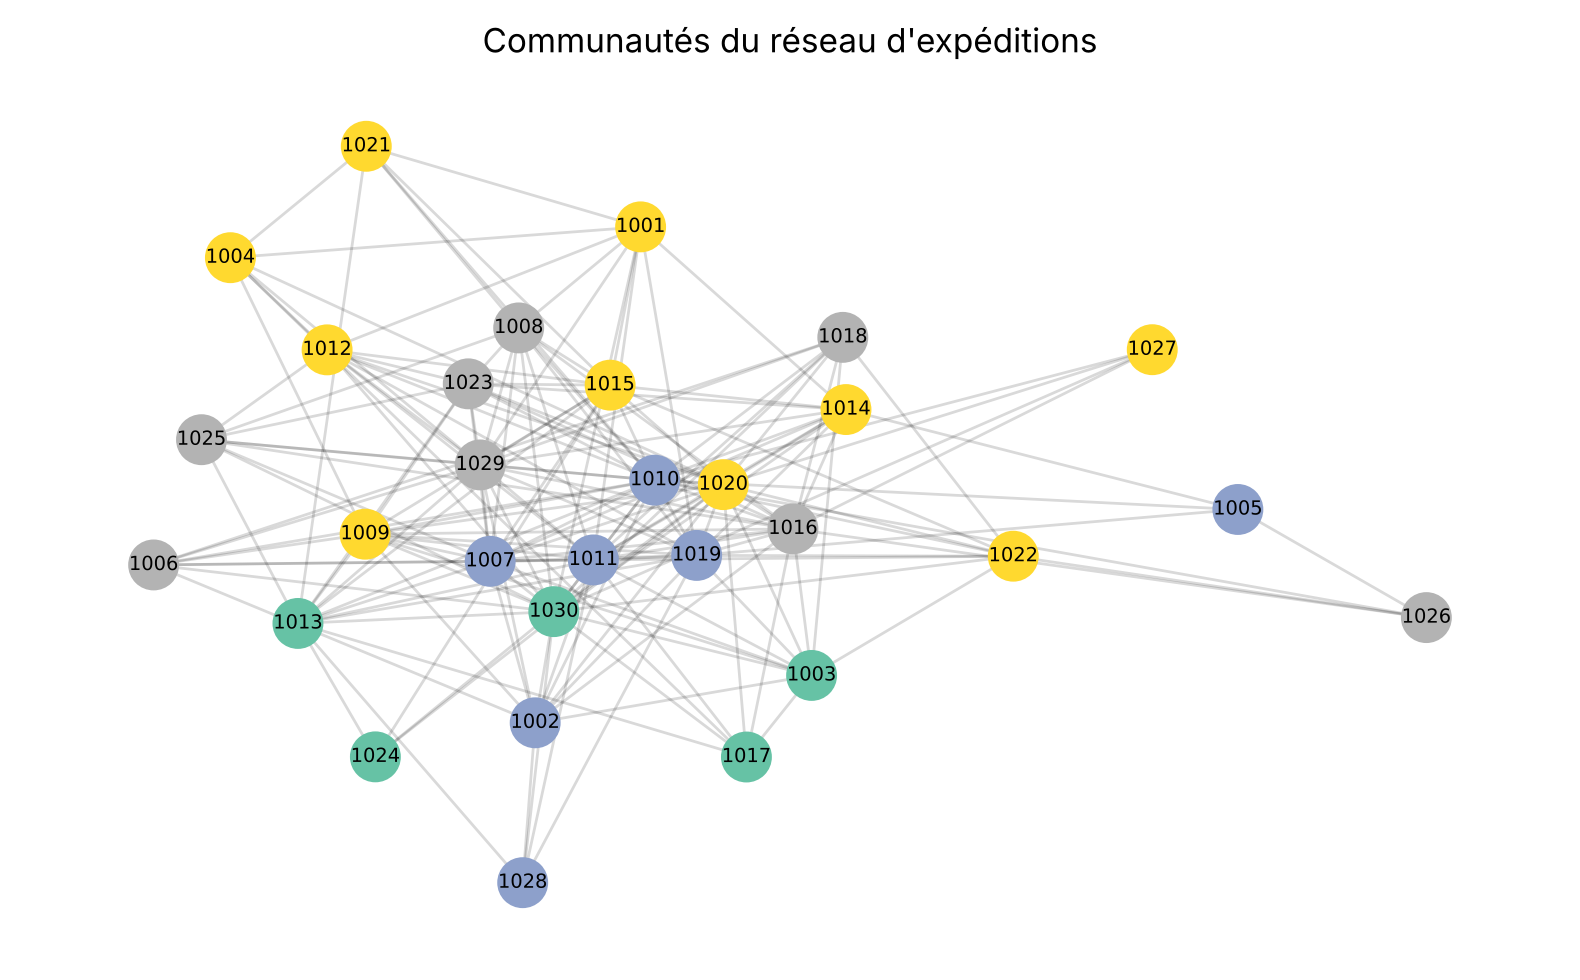

In [30]:
U = nx.Graph()
U.add_nodes_from(G.nodes)
for a, b, poids in G.edges(data="poids"):
    if U.has_edge(a, b):
        U[a][b]["poids"] += poids
    else:
        U.add_edge(a, b, poids=poids)

communautes = nx.community.louvain_communities(U, weight="poids", seed=0)
print("Communautés :", len(communautes))
print("Modularité :", round(nx.community.modularity(U, communautes, weight="poids"), 3))
for numero, communaute in enumerate(communautes, start=1):
    for code_site in communaute:
        noeuds.loc[code_site, "communaute"] = numero

position = nx.spring_layout(U, seed=0, weight="poids")
fig, ax = plt.subplots(figsize=(8, 5))
nx.draw_networkx_edges(U, position, alpha=0.15, ax=ax)
nx.draw_networkx_nodes(U, position, ax=ax, node_size=300,
    node_color=noeuds.loc[list(U.nodes), "communaute"], cmap="Set2")
nx.draw_networkx_labels(U, position, labels={code: code[-4:] for code in U.nodes}, font_size=7, ax=ax)
ax.set_title("Communautés du réseau d'expéditions")
ax.axis("off")
plt.tight_layout()
plt.show()

Louvain donne ici 4 communautés et une modularité d'environ 0,191. Une autre graine peut modifier leur composition. Le dessin représente les liens, pas les positions géographiques.

### Regarder les échanges les plus fréquents


In [31]:
noms_sites = sites.set_index("facility_code")["facility_name"]
principaux_liens = liens[~liens["origin_facility_code"].eq(liens["destination_facility_code"])].nlargest(5, "poids").copy()
principaux_liens["origine"] = principaux_liens["origin_facility_code"].map(noms_sites)
principaux_liens["destination"] = principaux_liens["destination_facility_code"].map(noms_sites)
display(principaux_liens[["origine", "destination", "poids"]])

axe_asterion = expeditions[
    expeditions["origin_facility_code"].eq("FCL-1011")
    & expeditions["destination_facility_code"].isin(["FCL-1007", "FCL-1010"])
]
print("Expéditions sur cet axe :", len(axe_asterion))
display(axe_asterion["declared_purpose"].value_counts().head(3))

,origine,destination,poids
75,Meridian Valenne Headquarters,Asterion Avelora Executive Clinic,44
77,Meridian Valenne Headquarters,Asterion Central Clinical Campus,19
83,Meridian Valenne Headquarters,Meridian Avelora Transfer Annex,17
150,Meridian Avelora Transfer Annex,Meridian Valenne Headquarters,17
229,Kintara Cave Authority Field Depot,Meridian Kintara Biological Aggregation Facility,8


Expéditions sur cet axe : 63


declared_purpose
temperature-controlled clinical programme delivery    26
scheduled stock transfer                              10
customer distribution                                  7
Name: count, dtype: int64

Les deux liens les plus fréquents vont du siège Meridian aux sites Asterion `FCL-1007` et `FCL-1010` : 44 et 19 expéditions, soit 63 au total. Le motif `temperature-controlled clinical programme delivery` apparaît 26 fois sur cet axe.

Ces deux sites sont aussi ceux des 30 retraits examinés plus haut.


## 11. Suivre les expéditions dans le temps - CM5

Nous comptons les départs par mois pour l'ensemble du fichier et pour l'axe Meridian vers les deux sites Asterion, défini plus haut. Le CM5 propose d'observer l'évolution temporelle et de la lisser avec une moyenne glissante (diapos 14 à 16).

Tous les mois entre le premier et le dernier départ sont représentés. Zéro signifie qu'aucune expédition n'est enregistrée ce mois-là dans le fichier ; cela ne prouve pas une absence d'activité réelle.


In [32]:
mois = pd.period_range(expeditions["dispatch_time"].min(),
                       expeditions["dispatch_time"].max(), freq="M")
mensuel = pd.DataFrame(index=mois)
for nom, table in {"Toutes les expéditions": expeditions,
                   "Meridian vers Asterion": axe_asterion}.items():
    comptage = table.groupby(table["dispatch_time"].dt.to_period("M")).size()
    mensuel[nom] = comptage.reindex(mois, fill_value=0)
mensuel.index = mensuel.index.to_timestamp()
mensuel.index.name = "mois"

print("Mois représentés :", len(mensuel))
print("Mois sans expédition enregistrée :", mensuel["Toutes les expéditions"].eq(0).sum())
display(mensuel.nlargest(3, "Toutes les expéditions"))


Mois représentés : 132
Mois sans expédition enregistrée : 33


,Toutes les expéditions,Meridian vers Asterion
mois,,
2023-09-01,32,3
2023-04-01,31,3
2024-06-01,30,3


La moyenne glissante utilise le mois affiché et les deux mois précédents. Cette fenêtre de trois mois lisse les variations d'un mois à l'autre. Les deux premières moyennes restent absentes, faute de trois mois disponibles. Nous gardons les comptes mensuels visibles pour voir les pics.


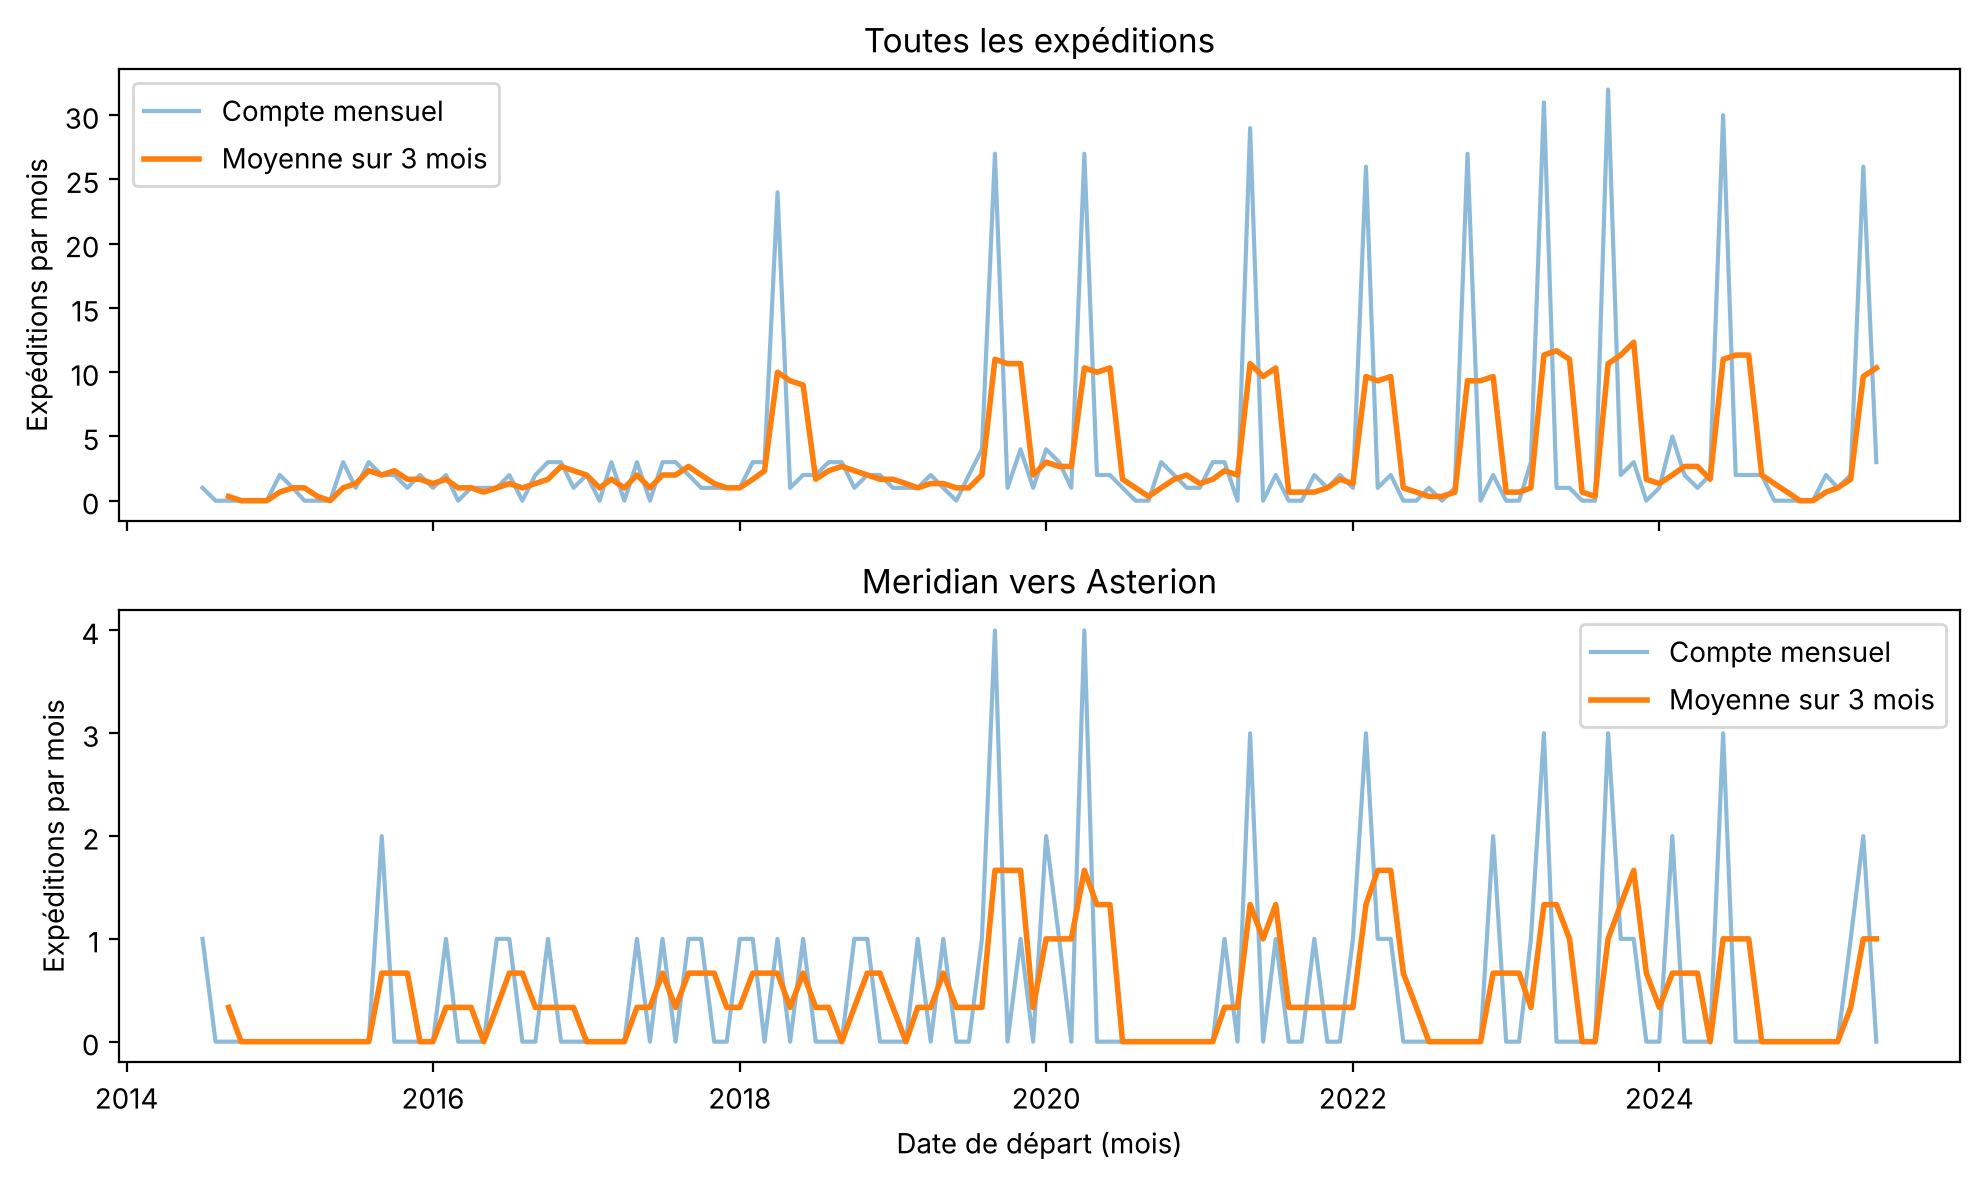

In [33]:
moyenne_3_mois = mensuel.rolling(window=3).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, nom in zip(axes, mensuel.columns):
    ax.plot(mensuel.index, mensuel[nom], alpha=0.5, label="Compte mensuel")
    ax.plot(moyenne_3_mois.index, moyenne_3_mois[nom],
            linewidth=2, label="Moyenne sur 3 mois")
    ax.set_title(nom)
    ax.set_ylabel("Expéditions par mois")
    ax.legend()
axes[-1].set_xlabel("Date de départ (mois)")
plt.tight_layout()
plt.show()


Le plus grand pic de l'ensemble est en septembre 2023 : 32 expéditions, dont 3 sur l'axe Meridian–Asterion. Sur cet axe, le maximum est de 4 expéditions, en septembre 2019 et en avril 2020. Les maxima des deux courbes se situent donc à des dates différentes. Le lissage facilite la lecture de l'évolution, sans établir de saisonnalité.


# Suite : creuser les pistes

Les parties 1 à 11 (Siyaman et Ilicia) ont montré un axe régulier entre Meridian et Asterion, et des retraits de stock sans référence chez Asterion. Les autres domaines nous ont aussi laissé des questions pour la logistique. On creuse ici ces pistes.

## 12. Un motif d'expédition pas encore étudié

Dans la partie 3, un motif rare n'a pas été regardé : « environmental and wildlife reference materials ». Qui envoie ces expéditions, et à qui ?

In [34]:
nom = partenaires.set_index("partner_code")["partner_name"]
site = sites.set_index("facility_code")["facility_name"]
exp = expeditions.assign(expediteur=expeditions["sender_partner_code"].map(nom),
                         destinataire=expeditions["receiver_partner_code"].map(nom),
                         origine=expeditions["origin_facility_code"].map(site),
                         destination=expeditions["destination_facility_code"].map(site))

faune = exp[exp["declared_purpose"] == "environmental and wildlife reference materials"]
faune[["shipment_number", "dispatch_time", "expediteur", "destinataire", "origine", "item_category", "temperature_control_class"]]

,shipment_number,dispatch_time,expediteur,destinataire,origine,item_category,temperature_control_class
57,SHP-2018-00004,2018-02-16 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Meridian Tembara Coastal Hub,biological_sample,2-8C
60,SHP-2018-00007,2018-03-23 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Kintara Cave Authority Field Depot,biological_sample,2-8C
85,SHP-2018-00032,2018-05-25 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Meridian Avelora Transfer Annex,biological_sample,2-8C
109,SHP-2019-00009,2019-08-09 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Meridian Tembara Coastal Hub,biological_sample,2-8C
126,SHP-2019-00026,2019-09-13 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Kintara Cave Authority Field Depot,biological_sample,2-8C
141,SHP-2019-00041,2019-11-08 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Meridian Avelora Transfer Annex,biological_sample,2-8C
164,SHP-2020-00019,2020-04-10 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Kintara Cave Authority Field Depot,biological_sample,2-8C
183,SHP-2020-00038,2020-06-12 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Meridian Avelora Transfer Annex,biological_sample,2-8C
198,SHP-2021-00007,2021-03-26 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Kintara Cave Authority Field Depot,biological_sample,2-8C
219,SHP-2021-00028,2021-05-21 09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Meridian Avelora Transfer Annex,biological_sample,2-8C


- Les 18 expéditions vont toutes d'Horizon vers Meridian.
- Ce sont des échantillons biologiques, gardés au froid (2-8 °C), et elles partent toujours à 9 h.
- Plusieurs partent du dépôt de l'autorité des grottes de Kintara.

## 13. Règles d'association

On vérifie si d'autres expéditions suivent un schéma aussi régulier. Pour chaque paire de caractéristiques (expéditeur, destinataire, catégorie, motif), on calcule la confiance de la règle « si A, alors B » et son lift (1 = aucun lien).

In [35]:
carac = pd.DataFrame({"expéditeur": exp["expediteur"], "destinataire": exp["destinataire"],
                      "catégorie": exp["item_category"], "motif": exp["declared_purpose"]})
regles = []
for a in carac.columns:
    for b in carac.columns:
        if a == b:
            continue
        compte = carac.groupby([a, b]).size()
        for (va, vb), n in compte.items():
            confiance = n / (carac[a] == va).sum()
            lift = confiance / (carac[b] == vb).mean()
            if n >= 10 and confiance >= 0.9:
                regles.append({"si": f"{a} = {va}", "alors": f"{b} = {vb}", "expéditions": n,
                               "confiance": round(confiance, 2), "lift": round(lift, 1)})
pd.DataFrame(regles).sort_values("lift", ascending=False)

,si,alors,expéditions,confiance,lift
2,motif = environmental and wildlife reference m...,expéditeur = Horizon Field Research Cooperative,18,1.00,12.9
6,motif = environmental and wildlife reference m...,catégorie = biological_sample,18,1.00,8.7
4,motif = environmental and wildlife reference m...,destinataire = Meridian BioLogistics,18,1.00,8.0
5,motif = temperature-controlled clinical progra...,destinataire = Asterion Clinical Institute,26,1.00,7.8
0,expéditeur = Horizon Field Research Cooperative,destinataire = Meridian BioLogistics,33,0.94,7.6
3,motif = temperature-controlled clinical progra...,expéditeur = Meridian BioLogistics,26,1.00,5.0
1,destinataire = Asterion Clinical Institute,expéditeur = Meridian BioLogistics,56,0.97,4.8


Les règles les plus fortes décrivent deux circuits :
- Horizon → Meridian, pour des échantillons biologiques « faune » ;
- Meridian → Asterion, pour des « livraisons de programme clinique » (l'axe de la partie 10).

## 14. Les expéditions d'Horizon et les visites des grottes

Public records montre qu'Horizon entre la nuit dans des grottes (sortie à 3 h). On compare la fin de chaque visite au départ de l'expédition « faune » qui suit.

In [36]:
acces = pd.read_csv("data_clean/public_records/site_access_case_events.csv", parse_dates=["event_time"])
fins = acces[(acces["activity"] == "access_completed")
             & (acces["requesting_organization_name"] == "Horizon Field Research Cooperative")]

lien = pd.merge_asof(faune.sort_values("dispatch_time"), fins.sort_values("event_time")[["site_code", "event_time"]],
                     left_on="dispatch_time", right_on="event_time")
lien["heures_apres"] = (lien["dispatch_time"] - lien["event_time"]).dt.total_seconds() / 3600
print("Visites d'Horizon :", len(fins), "- expéditions faune :", len(faune))
lien[["shipment_number", "site_code", "event_time", "dispatch_time", "heures_apres"]]

Visites d'Horizon : 18 - expéditions faune : 18


,shipment_number,site_code,event_time,dispatch_time,heures_apres
0,SHP-2018-00004,TMB-NAC,2018-02-16 03:00:00,2018-02-16 09:00:00,6.0
1,SHP-2018-00007,KNT-KES,2018-03-23 03:00:00,2018-03-23 09:00:00,6.0
2,SHP-2018-00032,AVL-MAR,2018-05-25 03:00:00,2018-05-25 09:00:00,6.0
3,SHP-2019-00009,TMB-PEL,2019-08-09 03:00:00,2019-08-09 09:00:00,6.0
4,SHP-2019-00026,KNT-LUM,2019-09-13 03:00:00,2019-09-13 09:00:00,6.0
5,SHP-2019-00041,AVL-VEL,2019-11-08 03:00:00,2019-11-08 09:00:00,6.0
6,SHP-2020-00019,KNT-SEN,2020-04-10 03:00:00,2020-04-10 09:00:00,6.0
7,SHP-2020-00038,AVL-ORR,2020-06-12 03:00:00,2020-06-12 09:00:00,6.0
8,SHP-2021-00007,KNT-KES,2021-03-26 03:00:00,2021-03-26 09:00:00,6.0
9,SHP-2021-00028,AVL-MAR,2021-05-21 03:00:00,2021-05-21 09:00:00,6.0


- Chaque expédition part exactement 6 h après la fin d'une visite (18 sur 18).
- L'expédition du 22 mars 2024 suit la visite de KNT-KES décrite dans le rapport de l'écologie.

On regarde aussi les expéditions citées dans les plaintes (public records).

In [37]:
plaintes = pd.read_csv("data_clean/public_records/regulatory_case_events.csv")
plaintes = plaintes[plaintes["initiating_source"] == "civil society referral"].drop_duplicates("case_number")
print("Plaintes qui citent une expédition faune :", plaintes["related_shipment_number"].isin(faune["shipment_number"]).sum(), "sur", len(plaintes))

Plaintes qui citent une expédition faune : 10 sur 10


Les 10 plaintes citent toutes une expédition « faune » d'Horizon vers Meridian.

## 15. Les livraisons de Meridian à Asterion et MRP-42

En santé, 8 dirigeants reçoivent plusieurs fois MRP-42 chez Asterion. On compare les dates de ces actes aux livraisons « programme clinique » de Meridian vers le même établissement (`FAC-AVL-201` et `FAC-VLN-101` en santé correspondent aux sites `FCL-1007` et `FCL-1010` en logistique).

In [38]:
actes = pd.read_csv("data_clean/health/clinical_procedures.csv", parse_dates=["performed_time"])
actes["site"] = actes["performing_facility_license"].map({"FAC-AVL-201": "FCL-1007", "FAC-VLN-101": "FCL-1010"})
cliniques = exp[exp["declared_purpose"] == "temperature-controlled clinical programme delivery"]

# Pour chaque livraison : y a-t-il un acte dans le même établissement exactement 8 jours après ?
for code_acte in ["MRP-42", "CARD-IMG", "AGE-PNL", "OCT-TRK"]:
    a = actes[actes["procedure_code"] == code_acte]
    suivies = sum(((a["site"] == l.destination_facility_code)
                   & (a["performed_time"].dt.normalize() == (l.dispatch_time + pd.Timedelta(days=8)).normalize())).any()
                  for l in cliniques.itertuples())
    print(f"{code_acte:9s} : {suivies} livraisons sur {len(cliniques)} suivies de cet acte 8 jours après")

MRP-42    : 26 livraisons sur 26 suivies de cet acte 8 jours après
CARD-IMG  : 0 livraisons sur 26 suivies de cet acte 8 jours après
AGE-PNL   : 0 livraisons sur 26 suivies de cet acte 8 jours après
OCT-TRK   : 0 livraisons sur 26 suivies de cet acte 8 jours après


- Chacune des 26 livraisons est suivie, 8 jours après, d'un MRP-42 dans le même établissement.
- Ce n'est pas le cas des autres actes.

On regarde qui reçoit ces MRP-42.

In [39]:
reperes = pd.read_csv("resultats/patients_reperes.csv")
mrp = actes[actes["procedure_code"] == "MRP-42"].copy()
dates = set(zip(cliniques["destination_facility_code"], (cliniques["dispatch_time"] + pd.Timedelta(days=8)).dt.normalize()))
mrp["apres_livraison"] = [(s, d) in dates for s, d in zip(mrp["site"], mrp["performed_time"].dt.normalize())]
mrp["dirigeant"] = mrp["patient_number"].isin(reperes[reperes["groupe"] == "MRP-42 répété"]["patient_number"])
pd.crosstab(mrp["apres_livraison"], mrp["dirigeant"])

dirigeant,False,True
apres_livraison,,
False,20,4
True,0,26


- Les 26 MRP-42 qui suivent une livraison sont tous donnés à un des 8 dirigeants.
- Les MRP-42 des autres patients ne suivent aucune livraison.

Dans la partie 5, Siyaman et Ilicia avaient trouvé 30 retraits de stock chez Asterion, aux motifs inhabituels (« controlled-area consumption », « procedure stock issue », « specialist programme issue ») et sans aucune référence. On compare leurs dates à celles des MRP-42.

In [40]:
retraits = ajustements[ajustements["adjustment_reason"].isin(
    ["controlled-area consumption", "procedure stock issue", "specialist programme issue"])].copy()
jours_mrp = set(zip(mrp["site"], mrp["performed_time"].dt.normalize()))
dirigeants_du_jour = set(zip(mrp.loc[mrp["dirigeant"], "site"], mrp.loc[mrp["dirigeant"], "performed_time"].dt.normalize()))

retraits["meme_jour_qu_un_MRP42"] = [(s, d) in jours_mrp for s, d in zip(retraits["facility_code"], retraits["adjustment_date"])]
retraits["MRP42_d_un_dirigeant"] = [(s, d) in dirigeants_du_jour for s, d in zip(retraits["facility_code"], retraits["adjustment_date"])]
print("Retraits le même jour et dans le même établissement qu'un MRP-42 :", retraits["meme_jour_qu_un_MRP42"].sum(), "sur", len(retraits))
print("... et ce MRP-42 est donné à un des 8 dirigeants :", retraits["MRP42_d_un_dirigeant"].sum(), "sur", len(retraits))
retraits[["adjustment_date", "facility_code", "adjustment_reason", "adjustment_quantity", "meme_jour_qu_un_MRP42"]]

Retraits le même jour et dans le même établissement qu'un MRP-42 : 30 sur 30
... et ce MRP-42 est donné à un des 8 dirigeants : 30 sur 30


,adjustment_date,facility_code,adjustment_reason,adjustment_quantity,meme_jour_qu_un_MRP42
0,2014-07-18,FCL-1007,specialist programme issue,-1.58,True
1,2015-09-10,FCL-1007,specialist programme issue,-2.70,True
4,2016-02-18,FCL-1010,procedure stock issue,-2.43,True
6,2016-06-16,FCL-1010,specialist programme issue,-2.58,True
7,2016-07-29,FCL-1007,controlled-area consumption,-1.89,True
8,2017-05-12,FCL-1007,controlled-area consumption,-2.12,True
9,2017-09-21,FCL-1007,controlled-area consumption,-1.86,True
10,2017-11-03,FCL-1010,procedure stock issue,-2.56,True
12,2018-01-26,FCL-1010,specialist programme issue,-2.31,True
14,2018-02-22,FCL-1010,controlled-area consumption,-2.09,True


- Les 30 retraits ont lieu le même jour, dans le même établissement, qu'un MRP-42 donné à l'un des 8 dirigeants.
- Le matériel retiré du stock « pour consommation » sert donc à préparer MRP-42.

Les retraits de la partie 5 ne sont plus inexpliqués : ils correspondent chacun à un MRP-42.

## 16. Bilan

### Ce que la logistique montre

- Les données sont globalement propres : quelques écarts de stock et des commandes reçues en partie, mais rien qui vise une organisation en particulier.
- Asterion retire du matériel de son stock sans référence de livraison, avec des motifs inhabituels (« consumption »).
- Deux circuits sont très réguliers :
  - Horizon envoie des échantillons biologiques, gardés au froid, à Meridian ;
  - Meridian envoie des « livraisons de programme clinique » à Asterion.

### Ce que ça résout dans nos pistes

- Écologie : ce qu'Horizon emporte des grottes part vers Meridian. Chaque envoi part 6 h après une visite de nuit, et les plaintes citent ces envois.
- Santé : les livraisons de Meridian à Asterion sont liées à MRP-42. Chaque livraison est suivie, 8 jours après, d'un MRP-42 donné à un des 8 dirigeants.
- Les 30 retraits de stock d'Asterion ont tous lieu le jour d'un MRP-42 : ce matériel sert à le préparer.
- On obtient une chaîne : grotte → Horizon → Meridian → Asterion → retrait de stock et MRP-42 pour les dirigeants.

### Ce qui reste à trouver

- Ce que contiennent vraiment les colis : seule la catégorie déclarée est connue, et elle peut être fausse (mémo CHAMELEO).
- Ce qui se passe chez Meridian entre l'arrivée des échantillons et le départ vers Asterion.
- Si les chauves-souris baissent après chaque visite d'Horizon (croisement avec l'écologie).
- Qui sont les 11 patients atypiques de la santé, qui ne reçoivent pas MRP-42.